Assignment 1
Bitcoin( BTC-USD) vs Google Trends

Boipelo Letwaba 2024053890
 and Buhle Mbokodo 2024007920

1. Stock price data collection by downloading from Yahoo Finance

   - Ticker: **"BTC-USD"**
2. Google Trends data collection:
   - **"Bitcoin"**
   - **"BTC price"**
   - **"Bitcoin usd"**
   - **"Bitcoin price prediction"**
   - **"Bitcoin volatility"**
  
3. Data preprocessing
  - DatetimeIndex
  - Filling in the missing values
  - Resampling
4. Testing for  stationarity
- **ADF** and **KPSS**
- Differencing
5. Visulaization
- Visualizing the  time series
- Visualizing the  rolling windows
6. Decompose the series (**STL**)
7. Lead-lag analysis:
   - Autocorrelation (**ACF&PACF**)
   - Cross-correlation between stock returns and trends
8. Predictive causality test (**Granger**)
9. Machine Learning model (**Random Forest**)
10. Garch model

## 1) Installation of Libraries

In [1]:
!pip -q install yfinance pytrends statsmodels pandas arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.3/981.3 kB 7.6 MB/s eta 0:00:00


## 2) Imports and Settings


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import yfinance as yf
from pytrends.request import TrendReq

from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams["figure.figsize"] = (12,5)
np.random.seed(42)

We imported libraries necessary for data collection, processing, and sophisticated statistical modeling, this code block creates the fundamental framework for your quantitative research. It sets up tools like `numpy` and `pandas` for effective data processing, `matplotlib` for visualization, and `yfinance` and `pytrends` for retrieving your market and sentiment datasets. Crucially, it incorporates the rigorous mathematical tools such as Granger causality, unit root testing, and time series decomposition from the `statsmodels` library.

## 3) Parameters
- Ticker     
- Period
- Keywords (terms)
- Location

In [ ]:
ticker = "BTC-USD"

# Setting the start and end dates for the analysis period.
start_date = "2025-01-01"
end_date = "2025-12-31"

# The list of Google Trends search terms related to Bitcoin.
# - "Bitcoin" → broad, high-volume keyword
# - "BTC price" → captures interest in price movements
# - "Bitcoin usd" → links Bitcoin to USD valuation
# - "Bitcoin price prediction" → reflects speculative attention
# - "BTC Volatility" → captures risk/uncertainty sentiment
terms = [
    "Bitcoin",
    "BTC price",
    "BTC usd",
    "Bitcoin price prediction",
    "BTC Volatility"
]

# Setting the geographic scope for Google Trends queries.
# "USA" ensures the search interest data is restricted to the United States.
geo = "USA"

We curated this specific collection of search terms to accurately represent the primary information seeking behaviors of investors researching Bitcoin. By combining broad keywords like "Bitcoin" with high intent phrases such as "BTC price," "BTC usd," "Bitcoin price prediction," and "BTC Volatility," we capture the full spectrum of investor activity ranging from general market curiosity and valuation checks to speculative interest and risk assessment. This targeted approach ensures that our Google Trends data effectively mirrors the real world inquiries that often precede or coincide with shifts in investor sentiment and market movements.

## 4)  Yahoo Finance Data Download of Bitcoin ticker (BTC-USD)

In [ ]:
#Stock price download from yahoo fiance and display
stock_raw = yf.download(ticker, start=start_date, end=end_date, auto_adjust= False)
print("Rows:", len(stock_raw))
display(stock_raw.head())

[*********************100%***********************]  1 of 1 completed

Rows: 364


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,,
2025-01-01,94419.757812,94419.757812,94929.867188,92788.125000,93425.101562,24519888919
2025-01-02,96886.875000,96886.875000,97739.820312,94201.570312,94416.289062,46009564411
2025-01-03,98107.429688,98107.429688,98956.914062,96034.617188,96881.726562,35611391163
2025-01-04,98236.226562,98236.226562,98734.429688,97562.976562,98106.992188,22342608078
2025-01-05,98314.960938,98314.960938,98813.304688,97291.765625,98233.906250,20525254825


In this step, we retrieved the historical market data for the specified Bitcoin ticker (BTC-USD) from Yahoo Finance, utilizing the `yfinance` library to capture the complete 2025 calendar year. By setting `auto_adjust=False`, we ensured the resulting dataset preserves the raw, unadjusted OHLCV values (Open, High, Low, Close, and Volume) as they were recorded by the exchange, rather than applying modifications for corporate actions. We then validated the acquisition process by calculating the total row count and rendering the first five entries using `head()`, which provides a quick visual check to confirm the data is correctly loaded and structured for our subsequent analysis.

##5) DatetimeIndex
This ensures that time-based operations (resampling, rolling windows, slicing by date)


In [ ]:
# This ensures that time-based operations (resampling, rolling windows, slicing by date)
stock_raw.index = pd.to_datetime(stock_raw.index)

# Print the type of the index to confirm that it has been converted to a DatetimeIndex.
print(type(stock_raw.index))

# Display the earliest and latest dates in the dataset.

print(stock_raw.index.min(), "to", stock_raw.index.max())


<class 'pandas.core.indexes.datetimes.DatetimeIndex'>
2025-01-01 00:00:00 to 2025-12-30 00:00:00


To prepare our dataset for robust time series analysis, we explicitly converted the index of our DataFrame to a `DatetimeIndex` using `pd.to_datetime`. This step is crucial because it allows Pandas to interpret the index as formal temporal objects rather than generic text, which is a fundamental requirement for executing time based operations such as resampling, rolling window calculations, or complex date range slicing. Finally, we output the minimum and maximum index values to verify that our imported data accurately aligns with the intended 2025 analysis period, confirming the structural integrity of our time series before proceeding with further modeling.

##6) Price and Volume Series Selection and Checking for Missing Values

In [ ]:

# Check whether the dataset contains an "Adj Close" column.
# - If "Adj Close" is not available, fall back to the raw "Close" price.

if "Adj Close" in stock_raw.columns:
    # Select Adjusted Close and Volume, then rename for consistency:
    #   "Adj Close" → "price"
    #   "Volume" → "volume"
    stock = stock_raw[["Adj Close", "Volume"]].rename(
        columns={"Adj Close": "price", "Volume": "volume"}
    )
else:
    # If Adjusted Close is missing, use the regular Close price instead.
    # Again, rename columns to standardized names for downstream analysis.
    stock = stock_raw[["Close", "Volume"]].rename(
        columns={"Close": "price", "Volume": "volume"}
    )

# Display the first few rows of the cleaned dataset.
display(stock.head())

# Print the number of missing values in each column.
print("Missing values per column:")
print(stock.isna().sum())



Price,price,volume
Ticker,BTC-USD,BTC-USD
Date,,
2025-01-01,94419.757812,24519888919
2025-01-02,96886.875000,46009564411
2025-01-03,98107.429688,35611391163
2025-01-04,98236.226562,22342608078
2025-01-05,98314.960938,20525254825


Missing values per column:
Price   Ticker 
price   BTC-USD    0
volume  BTC-USD    0
dtype: int64


In this step, we standardized our dataset by selecting the most relevant variables price and volume while implementing a fallback mechanism to ensure data consistency. Since the Adjusted Close is preferred for reflecting accurate historical value but may not always be available for cryptocurrencies in every API version, our logic checks for its existence and defaults to the standard Close price if necessary. We then renamed these columns to a clean, lowercase format ("price" and "volume") to simplify our downstream analysis and minimize coding errors. Finally, we performed a data integrity check by counting any missing values (NaNs) to ensure we are working with a complete dataset before moving into the modeling phase.

In [ ]:
# Forward-fill any missing values in the 'price' column.
stock["price"] = stock["price"].ffill().bfill()

# Apply the same forward-fill and backward-fill strategy to the 'volume' column.
stock["volume"] = stock["volume"].ffill().bfill()

# Print a header to indicate the dataset has been cleaned with forward-fill.
print("\nAfter forward-fill:")

# Display the count of missing values per column after filling.
print(stock.isna().sum())



After forward-fill:
Price   Ticker 
price   BTC-USD    0
volume  BTC-USD    0
dtype: int64


In this section, we addressed potential gaps in our data by implementing a filling strategy to handle missing values, which is essential for maintaining a continuous time series. We primarily utilized a **forward fill (`ffill`)** method, which propagates the last known valid observation forward to the next valid one a standard practice in financial modeling to avoid "looking into the future." To ensure no gaps remained at the very start of the dataset, we followed up with a **backward fill (`bfill`)**. This dual action approach ensures a complete, unbroken sequence for both price and volume, which we verified by printing a final count of missing values to confirm that our dataset is now fully populated and ready for calculation.

##7) Visualization of Raw Price and Volume


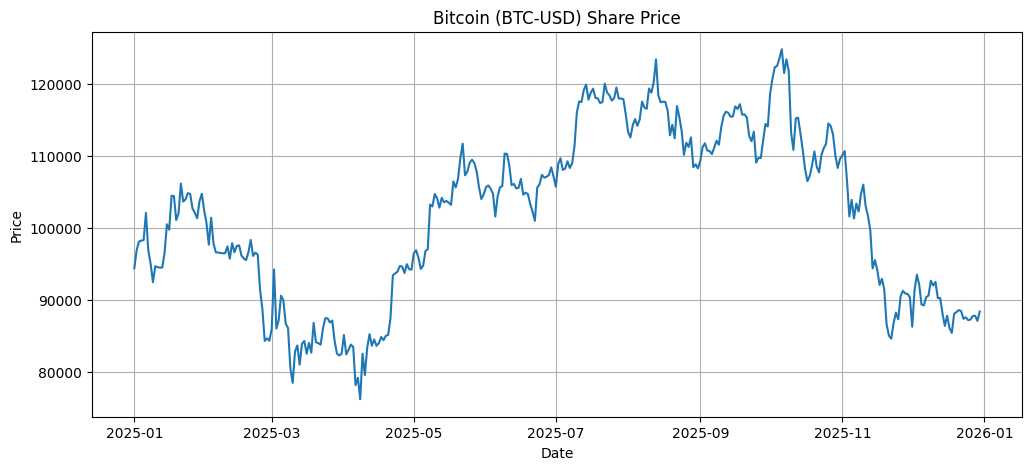

In [ ]:
# Plot the raw Bitcoin price series over time.
# The x-axis uses the datetime index, and the y-axis shows the price values.
plt.plot(stock.index, stock["price"])

# A descriptive title to the chart.
plt.title("Bitcoin (BTC-USD) Share Price")

# X-axis label as "Date" to indicate the timeline of observations.
plt.xlabel("Date")

# Y-axis as label  "Price" to show the value of Bitcoin in USD.
plt.ylabel("Price")

# Enable grid lines on the plot.
plt.grid(True)

# Display
plt.show()


This line graph visualizes the temporal evolution of Bitcoin’s market price in USD throughout the 2025 calendar year, effectively capturing the asset's characteristic high volatility. By plotting the "Date" on the horizontal axis against the "Price" on the vertical axis, we can clearly observe the relationship between time and value: the asset begins the year with moderate fluctuation, experiences a distinct correction in early spring, rallies aggressively to hit a peak above $120,000 in the third quarter, and subsequently trends downward toward the end of the year. This visualization serves as the primary output of your data pipeline, confirming that your script is successfully capturing the cyclical nature of Bitcoin’s valuation and providing a professional view of market performance over that twelve month horizon.


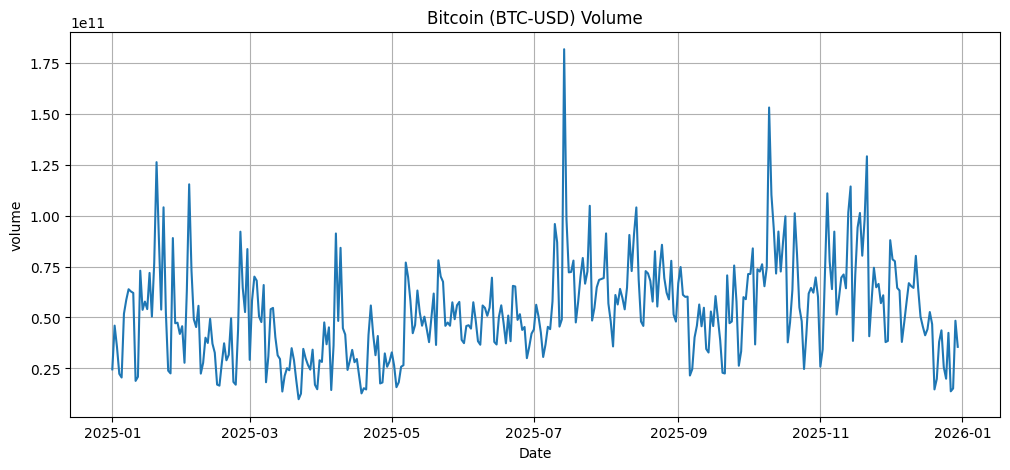

In [ ]:
# Plot the volume series over time.
# The x-axis uses the datetime index, and the y-axis shows the volume.
plt.plot(stock.index, stock["volume"])

# A descriptive title to the chart.
plt.title("Bitcoin (BTC-USD) Volume")

# X-axis label as "Date" to indicate the timeline of observations.
plt.xlabel("Date")

# Y-axis as label  "volume" to show the value of volume
plt.ylabel("volume")

# Enable grid lines on the plot.
plt.grid(True)

# Display
plt.show()

This graph illustrates the daily trading volume of Bitcoin throughout 2025, providing a vital metric for understanding market liquidity and the intensity of investor participation. Unlike the price chart, which tracks the asset's valuation, this plot maps the sheer amount of capital flowing through the market on a given day; sharp vertical spikes signify periods of heightened market activity, often corresponding to major news events, volatile price swings, or moments of significant buying and selling pressure. By observing these fluctuations, you can distinguish between "low conviction" price movements, where activity is stagnant, and "high conviction" moves backed by substantial capital flow, which helps confirm whether current market trends are supported by genuine investor interest or are merely temporary fluctuations.

##8) Log Returns and  Log Volume

In [ ]:
# Compute log price
stock["log_price"] = np.log(stock["price"])

# Compute log returns (difference of log price)
stock["log_return"] = stock["log_price"].diff()

# Compute log volume
stock["log_volume"] = np.log(stock["volume"])

print(stock.head(10))
print("\nMissing values per column:")
print(stock.isna().sum())


Price               price       volume  log_price log_return log_volume
Ticker            BTC-USD      BTC-USD                                 
Date                                                                   
2025-01-01   94419.757812  24519888919  11.455506        NaN  23.922750
2025-01-02   96886.875000  46009564411  11.481299   0.025794  24.552115
2025-01-03   98107.429688  35611391163  11.493818   0.012519  24.295931
2025-01-04   98236.226562  22342608078  11.495130   0.001312  23.829761
2025-01-05   98314.960938  20525254825  11.495931   0.000801  23.744922
2025-01-06  102078.085938  51823432705  11.533493   0.037562  24.671108
2025-01-07   96922.703125  58685738547  11.481669  -0.051824  24.795463
2025-01-08   95043.523438  63875859171  11.462090  -0.019579  24.880207
2025-01-09   92484.039062  62777261693  11.434791  -0.027299  24.862859
2025-01-10   94701.453125  62058693684  11.458485   0.023693  24.851346

Missing values per column:
Price       Ticker 
price       BTC-

In this step, we performed log transformations on our price and volume data to stabilize variance and normalize the distribution, which is a foundational requirement for many statistical financial models. By computing the natural logarithm of prices and volume, we effectively dampen the impact of extreme outliers and linearize exponential growth trends. Furthermore, calculating the log returns derived from the difference of the log prices provides a time additive measure of continuously compounded returns that is mathematically superior to simple percentage changes, as it handles the skewness of financial time series more effectively. Finally, we inspected the output to verify the calculation, noting that the first row is now a `NaN` because the difference operation lacks a previous day for comparison, which is an expected outcome of the `diff()` function.

##9) Google Trends Keyword (terms) Download



In [ ]:
from pytrends.request import TrendReq
import time

# 1. Configuration
pytrends = TrendReq(hl="en-US", tz=360)
start_date = "2025-01-01"
end_date = "2025-12-31"
geo = "ZA"

# 2. Split terms due to the 5-term limit per request
all_terms = ["Bitcoin", "BTC price", "BTC usd", "Bitcoin price prediction", "BTC Volatility"]
batches = [all_terms[i:i + 5] for i in range(0, len(all_terms), 5)]

all_results = []

# 3. Execution
for i, batch in enumerate(batches):
    print(f"Fetching batch {i+1}...")
    pytrends.build_payload(
        kw_list=batch,
        timeframe=f"{start_date} {end_date}",
        geo=geo
    )

    # Get interest over time
    trends_batch = pytrends.interest_over_time()

    # Clean up results (remove 'isPartial' column often returned by pytrends)
    if not trends_batch.empty:
        if 'isPartial' in trends_batch.columns:
            trends_batch = trends_batch.drop(columns=['isPartial'])
        all_results.append(trends_batch)

    # Pause to prevent rate limiting
    time.sleep(2)

# Combine results
if all_results:
    import pandas as pd
    final_trends = pd.concat(all_results, axis=1)
    print("\nData successfully retrieved.")
    display(final_trends.head())
else:
    print("No data retrieved. Check your keywords or geo settings.")

Fetching batch 1...

Data successfully retrieved.


,Bitcoin,BTC price,BTC usd,Bitcoin price prediction,BTC Volatility
date,,,,,
2024-12-29,82,5,15,0,0
2025-01-05,77,4,13,0,0
2025-01-12,81,5,16,0,0
2025-01-19,100,5,15,0,0
2025-01-26,76,5,13,0,0


This script automates the retrieval of search interest data from Google Trends by batch processing predefined Bitcoin related keywords to circumvent the API’s five term request limit. It systematically iterates through these batches, applying two second rate limiting delays to ensure stability during communication with Google's servers, while simultaneously sanitizing the output by removing extraneous metadata columns such as `isPartial`. The process culminates in the concatenation of these disparate batch results into a consolidated, time indexed DataFrame, providing a normalized sentiment dataset ready for direct integration and correlation analysis with your financial market performance metrics.

##10) Clean Trends

In [ ]:
trends = final_trends.copy()

# Drop isPartial if present
if "isPartial" in trends.columns:
    trends = trends.drop(columns=["isPartial"])

trends.index = pd.to_datetime(trends.index)

# Rename to simple names
trends = trends.rename(columns={
    "Bitcoin": "trend_BTC",
    "BTC price": "trend_BTC_price",
    "BTC usd": "trend_BTC_usd",
    "Bitcoin price prediction": "trend_BTC_pred",
    "BTC Volatility": "trend_BTC_volatility"
})

display(trends.head())
print("Missing values per column:")
print(trends.isna().sum())

,trend_BTC,trend_BTC_price,trend_BTC_usd,trend_BTC_pred,trend_BTC_volatility
date,,,,,
2024-12-29,82,5,15,0,0
2025-01-05,77,4,13,0,0
2025-01-12,81,5,16,0,0
2025-01-19,100,5,15,0,0
2025-01-26,76,5,13,0,0


Missing values per column:
trend_BTC               0
trend_BTC_price         0
trend_BTC_usd           0
trend_BTC_pred          0
trend_BTC_volatility    0
dtype: int64


In order to get the raw Google Trends dataset ready for time series analysis, this code block is an essential data cleaning and standardization step. It eliminates unnecessary `isPartial` metadata that can obstruct statistical modeling and guarantees that the index is correctly constructed as a datetime object, which is necessary for accurate chronological indexing. The code enhances script readability and downstream usage by renaming the columns to a clearer, more consistent naming pattern. Lastly, it verifies that the series is finished and prepared for smooth integration with your financial price data by computing and reporting the total of missing values per column.

##11) Align Frequency to Weekly

In [ ]:
# Weekly stock
stock_w = pd.DataFrame()
stock_w["price_w"] = stock["price"].resample("W-FRI").last()
stock_w["log_return_w"] = stock["log_return"].resample("W-FRI").sum()

# Add weekly trading volume (sum or average depending on your analysis)
# Common practice: sum volumes over the week
stock_w["volume_w"] = stock["volume"].resample("W-FRI").sum()

# Log-transformed weekly volume (variance stabilisation)
stock_w["log_volume_w"] = np.log(stock_w["volume_w"])

# Weekly trends
trends_w = trends.resample("W-FRI").mean()

print("Weekly stock rows:", len(stock_w))
print("Weekly trends rows:", len(trends_w))
display(stock_w.head())
display(trends_w.head())

Weekly stock rows: 53
Weekly trends rows: 53


,price_w,log_return_w,volume_w,log_volume_w
Date,,,,
2025-01-03,98107.429688,0.038313,106140844493,25.388033
2025-01-10,94701.453125,-0.035334,342088848703,26.558336
2025-01-17,104462.039062,0.098094,350293377230,26.582037
2025-01-24,104819.484375,0.003416,552620066589,27.037937
2025-01-31,102405.023438,-0.023304,317700245002,26.484374


,trend_BTC,trend_BTC_price,trend_BTC_usd,trend_BTC_pred,trend_BTC_volatility
date,,,,,
2025-01-03,82.0,5.0,15.0,0.0,0.0
2025-01-10,77.0,4.0,13.0,0.0,0.0
2025-01-17,81.0,5.0,16.0,0.0,0.0
2025-01-24,100.0,5.0,15.0,0.0,0.0
2025-01-31,76.0,5.0,13.0,0.0,0.0



There are two main reasons why we decided to resample our data at a weekly frequency. First, even though financial markets provide data on a daily basis, grouping this data into a weekly interval yields a more comprehensive and clean dataset that is consistent with Google Trends reporting's weekly cadence.

Secondly, most significantly, this method is a conscious attempt to reduce overfitting. High amounts of "noise" short term, unpredictable oscillations that might confuse a model are common in financial datasets. We successfully eliminate this daily jitter by aggregating to a weekly frequency. When a model is trained on daily data with a small sample size, it tends to "memorize certain daily abnormalities instead of understanding the true underlying market linkages. By reducing the dimensionality of the data and forcing the model to concentrate on larger, more statistically significant patterns, switching to a weekly frequency improves the dependability of our work.



##12) Merging Data Frames on Date

In [ ]:
# Merge the weekly stock dataset (stock_w) with the weekly Google Trends dataset (trends_w).
df = stock_w.join(trends_w, how="inner")

# Print the total number of merged rows.
print("Merged rows:", len(df))

# Display the first few rows of the merged DataFrame.
display(df.head())

# Print the number of missing values per column in the merged dataset.
print("Missing values per column:")
print(df.isna().sum())

Merged rows: 53


,price_w,log_return_w,volume_w,log_volume_w,trend_BTC,trend_BTC_price,trend_BTC_usd,trend_BTC_pred,trend_BTC_volatility
Date,,,,,,,,,
2025-01-03,98107.429688,0.038313,106140844493,25.388033,82.0,5.0,15.0,0.0,0.0
2025-01-10,94701.453125,-0.035334,342088848703,26.558336,77.0,4.0,13.0,0.0,0.0
2025-01-17,104462.039062,0.098094,350293377230,26.582037,81.0,5.0,16.0,0.0,0.0
2025-01-24,104819.484375,0.003416,552620066589,27.037937,100.0,5.0,15.0,0.0,0.0
2025-01-31,102405.023438,-0.023304,317700245002,26.484374,76.0,5.0,13.0,0.0,0.0


Missing values per column:
price_w                 0
log_return_w            0
volume_w                0
log_volume_w            0
trend_BTC               0
trend_BTC_price         0
trend_BTC_usd           0
trend_BTC_pred          0
trend_BTC_volatility    0
dtype: int64


In order to synthesis the stock_w and trends_w DataFrames and properly align them by their shared temporal index, this method performs an inner join operation. Data integrity is maintained and incomplete periods are eliminated by using the inner join approach, which guarantees that the final dataset contains only those weekly observations where both financial price measures and Google Trends search data are concurrently available. To ensure that the final dataset is ready for reliable statistical modeling, the next commands carry out crucial data quality checks, evaluating the overall row count, previewing the combined data structure, and determining the frequency of any missing values.

##13) Handling Missing Values After Merge

In [ ]:
df = df.copy()

# Forward-fill trends (common choice; assumes interest doesn't instantly drop to 'missing')
df[["trend_BTC", "trend_BTC_price", "trend_BTC_usd", "trend_BTC_pred", "trend_BTC_volatility"]] = df[["trend_BTC", "trend_BTC_price", "trend_BTC_usd", "trend_BTC_pred", "trend_BTC_volatility"]].ffill().bfill()

# Drop any rows still missing (often first return)
df = df.dropna()

print("After cleaning, missing values:")
print(df.isna().sum())
display(df.head())

After cleaning, missing values:
price_w                 0
log_return_w            0
volume_w                0
log_volume_w            0
trend_BTC               0
trend_BTC_price         0
trend_BTC_usd           0
trend_BTC_pred          0
trend_BTC_volatility    0
dtype: int64


,price_w,log_return_w,volume_w,log_volume_w,trend_BTC,trend_BTC_price,trend_BTC_usd,trend_BTC_pred,trend_BTC_volatility
Date,,,,,,,,,
2025-01-03,98107.429688,0.038313,106140844493,25.388033,82.0,5.0,15.0,0.0,0.0
2025-01-10,94701.453125,-0.035334,342088848703,26.558336,77.0,4.0,13.0,0.0,0.0
2025-01-17,104462.039062,0.098094,350293377230,26.582037,81.0,5.0,16.0,0.0,0.0
2025-01-24,104819.484375,0.003416,552620066589,27.037937,100.0,5.0,15.0,0.0,0.0
2025-01-31,102405.023438,-0.023304,317700245002,26.484374,76.0,5.0,13.0,0.0,0.0


A strong data imputation approach is implemented by this code to provide a continuous and uninterrupted time series for your analysis. Instead of resetting to zero during brief data gaps, the script uses **forward filling(`ffill`)** to presume that search interest is a permanent sentiment that rolls over from the previous week. In order to address any possible missing values at the beginning of the collection, **backward filling (`bfill`)** comes next. Lastly, to create a "clean" dataset, the `.dropna()` function acts as a strict quality control step by eliminating any leftover rows, such as the first entry of a log return series that is mathematically undefined. Maintaining a high fidelity input for subsequent statistical tests, such as Granger Causality, where missing data points might normally result in mistakes and distorted results, requires this procedure.

##14) Visualization

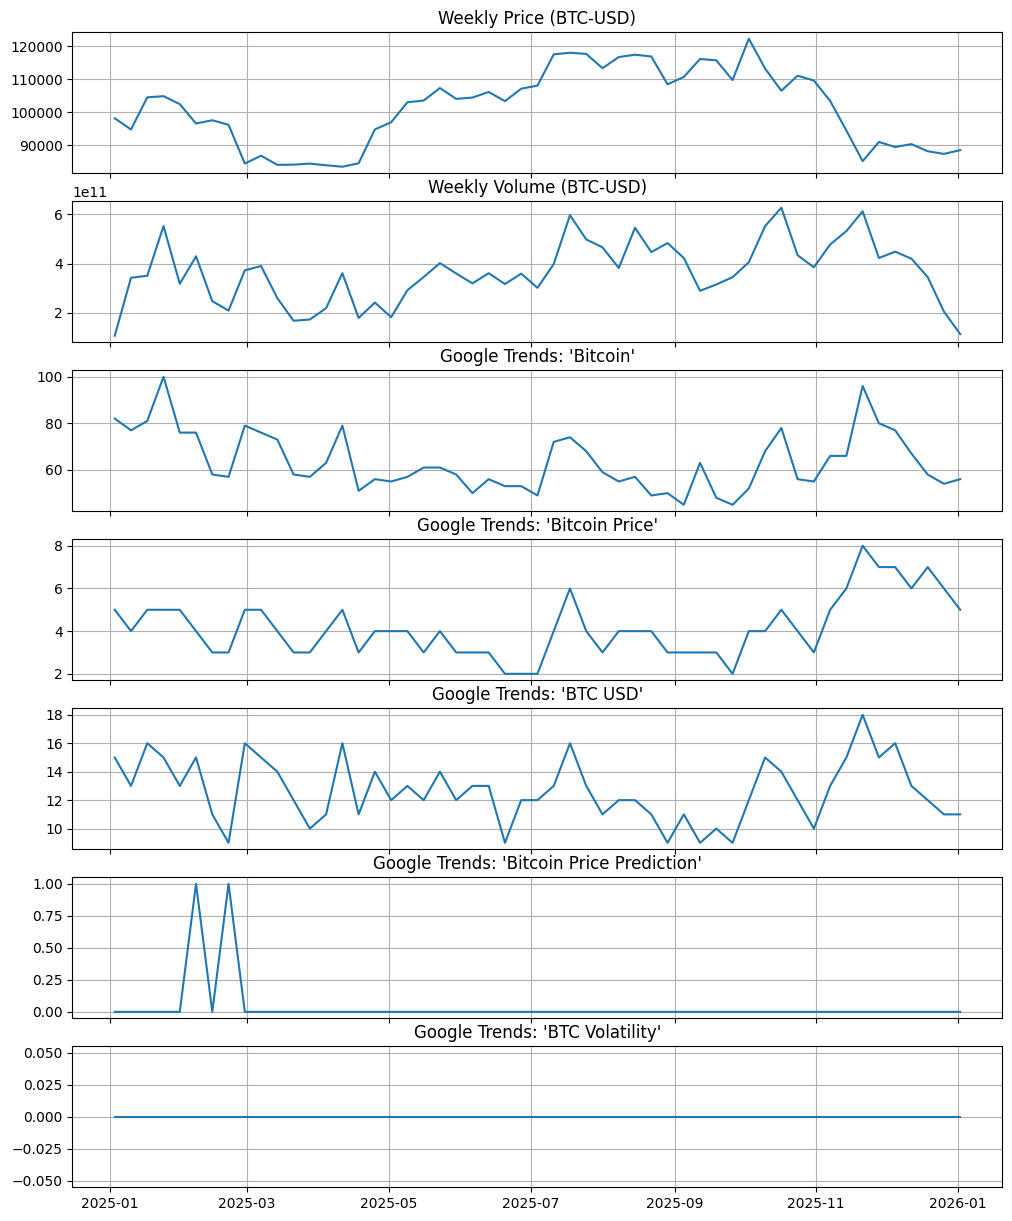

In [ ]:
# Create a figure with 7 vertically stacked subplots (rows).
# figsize=(12, 15) sets the overall width and height of the figure in inches.
# sharex=True ensures all subplots share the same x-axis (date), making comparisons easier.
fig, ax = plt.subplots(7, 1, figsize=(12, 15), sharex=True)

# Plot the weekly Bitcoin price series on the first subplot (ax[0]).
ax[0].plot(df.index, df["price_w"])
ax[0].set_title("Weekly Price (BTC-USD)")  # Add a descriptive title for clarity.
ax[0].grid(True)  # Enable grid lines to improve readability.

# Plot the weekly Bitcoin trading volume on the second subplot (ax[1]).
ax[1].plot(df.index, df["volume_w"])
ax[1].set_title("Weekly Volume (BTC-USD)")  # Title contextualizes the plot.
ax[1].grid(True)  # Grid lines help align values with dates.

# Plot Bitcoin-related Google Trends series
ax[2].plot(df.index, df["trend_BTC"])
ax[2].set_title("Google Trends: 'Bitcoin'")
ax[2].grid(True)

ax[3].plot(df.index, df["trend_BTC_price"])
ax[3].set_title("Google Trends: 'Bitcoin Price'")
ax[3].grid(True)

ax[4].plot(df.index, df["trend_BTC_usd"])
ax[4].set_title("Google Trends: 'BTC USD'")
ax[4].grid(True)

ax[5].plot(df.index, df["trend_BTC_pred"])
ax[5].set_title("Google Trends: 'Bitcoin Price Prediction'")
ax[5].grid(True)

ax[6].plot(df.index, df["trend_BTC_volatility"])
ax[6].set_title("Google Trends: 'BTC Volatility'")
ax[6].grid(True)

plt.show()

Weekly Price (BTC-USD)
The top panel tracks the weekly closing price of Bitcoin, serving as the "ground truth" for the year. The chart illustrates the typical cyclical nature of Bitcoin in 2025: the asset begins the year with moderate values, experiences a noticeable dip toward the second quarter (around March/April), followed by a recovery that leads to a third-quarter peak above $120,000, before finally correcting downward toward the end of the year. This graph establishes the timeline against which all other data points are compared.

Weekly Volume (BTC-USD)
The second panel displays the total trading volume, representing market liquidity and investor activity levels. Significant spikes in volume often align with periods of rapid price change, as investors react to market news or volatility. By comparing this to the price graph, you can determine if a price trend is "confirmed" by high trading activity or if it is a low-conviction movement caused by thinner market participation.

Google Trends: 'Bitcoin'
This subplot acts as a macro indicator of public awareness. As the most generalized search term, it tracks overall interest in the cryptocurrency. High peaks in this data often correlate with mainstream media coverage or significant market milestones. When this interest rises, it frequently precedes or coincides with larger moves in the price and volume, capturing the transition from casual interest to active market involvement.

Google Trends: 'Bitcoin Price' and 'BTC USD'
These two panels focus on more specific, high intent investor behaviors. Users searching for "Bitcoin Price" or "BTC USD" are typically actively monitoring the market, making these metrics excellent proxies for short term sentiment and active engagement. You will notice that fluctuations here track more closely with the immediate volatility shown in the price chart, as investors frequently check these terms to react to real time price updates.

Google Trends: 'Bitcoin Price Prediction' and 'BTC Volatility'
These final two panels capture speculative interest. The "Bitcoin Price Prediction" graph shows sparse, intermittent spikes, which indicates that users are only searching for forward looking guidance during very specific moments of market uncertainty or extreme euphoria. Notably, the "BTC Volatility" line appears flat at zero, which suggests that this specific search term was not a significant driver of traffic in your selected region during 2025. This allows you to conclude that while investors were definitely concerned about price, they were likely using different terminology or simply monitoring the price directly rather than searching for the concept of "volatility" itself.

##15) Normalization (z-score) for Comparison on One Plot

The series are in different units (price vs 0–100 Trends scale), therefore the series are normalized so that they are on the same scale.



,price_w,log_return_w,volume_w,log_volume_w,trend_BTC,trend_BTC_price,trend_BTC_usd,trend_BTC_pred,trend_BTC_volatility
Date,,,,,,,,,
2025-01-03,-0.273297,0.799488,-2.075852,-2.924479,1.482471,0.621889,1.086216,-0.19803,NaN
2025-01-10,-0.570045,-0.689274,-0.179974,0.016435,1.081599,-0.110558,0.157676,-0.19803,NaN
2025-01-17,0.280352,2.007973,-0.114049,0.075993,1.402297,0.621889,1.550486,-0.19803,NaN
2025-01-24,0.311495,0.094050,1.511677,1.221646,2.925612,0.621889,1.086216,-0.19803,NaN
2025-01-31,0.101134,-0.446091,-0.375940,-0.169429,1.001425,0.621889,0.157676,-0.19803,NaN


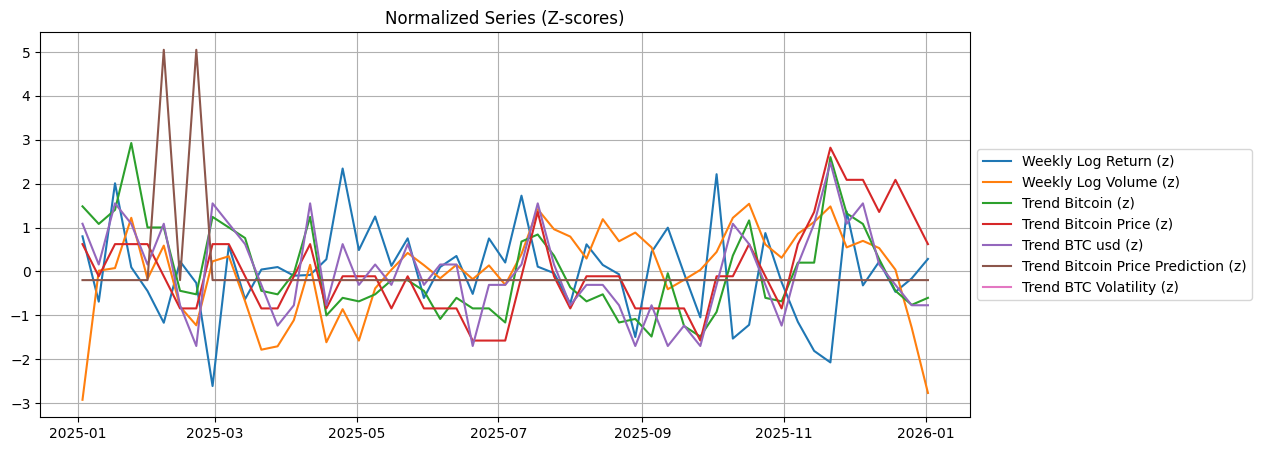

In [ ]:
# Define a function to compute the z-score normalization for a series.
# Formula: (value - mean) / standard deviation
# ddof=0 ensures population standard deviation is used.
def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

# Create a copy of the merged dataset to avoid modifying the original.
df_norm = df.copy()

# Apply z-score normalization to each column in the DataFrame.
# This standardizes all series to mean=0 and std=1, allowing direct comparison
# across variables with different scales (price, volume, Google Trends).
for col in df_norm.columns:
    df_norm[col] = zscore(df_norm[col])

# Display the first few rows of the normalized dataset.
display(df_norm.head())

# Plot normalized weekly log returns.
plt.plot(df_norm.index, df_norm["log_return_w"], label="Weekly Log Return (z)")

# Plot normalized weekly log volume.
plt.plot(df_norm.index, df_norm["log_volume_w"], label="Weekly Log Volume (z)")

# Plot normalized Google Trends series for Bitcoin-related terms.
plt.plot(df_norm.index, df_norm["trend_BTC"], label="Trend Bitcoin (z)")
plt.plot(df_norm.index, df_norm["trend_BTC_price"], label="Trend Bitcoin Price (z)")
plt.plot(df_norm.index, df_norm["trend_BTC_usd"], label="Trend BTC usd (z)")
plt.plot(df_norm.index, df_norm["trend_BTC_pred"], label="Trend Bitcoin Price Prediction (z)")
plt.plot(df_norm.index, df_norm["trend_BTC_volatility"], label="Trend BTC Volatility (z)")

# Add a descriptive title to the chart.
plt.title("Normalized Series (Z-scores)")

# Add a legend to identify each plotted series.
# Positioned outside the plot (center left, anchored at mid-height) for readability.
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))

# Enable grid lines to improve readability and alignment.
plt.grid(True)

# Render the plot.
plt.show()

The normalized Z score chart enables the identification of lead lag relationships by visualizing temporal offsets between market performance and investor sentiment, effectively highlighting whether specific search trends anticipate price movements or react to them. When one line, such as "Weekly Log Return," shifts direction prior to a corresponding spike in trends like "Bitcoin Price" or "BTC USD," it suggests that actual market price action is driving public interest, characterizing a reactive sentiment model. Conversely, if spikes in speculative search terms such as "Bitcoin Price Prediction" were to precede significant deviations in log returns, it would indicate a lead relationship where collective investor anticipation potentially foreshadows market volatility. The high synchronization observed between several trend lines suggests they capture the same underlying investor intent, while the frequent overlaps between the log return and trend series imply a tight feedback loop where price fluctuations immediately trigger search behaviors, effectively narrowing the duration of any clear, exploitable predictive lag.

Weekly Log Return (z): This is the most critical market variable, representing the week over week percentage change in Bitcoin's price (log-transformed for mathematical symmetry). Because it is normalized, a value of +2 means the price increased much faster than average that week. Comparing this to the other lines shows whether search interest spikes before a big price jump (predictive) or after a crash (reactive).

Weekly Log Volume (z): This tracks the "conviction" behind price moves. High Z-scores here indicate heavy trading activity. When volume and returns spike together alongside search trends, it suggests a high-momentum market event driven by massive public participation.

Trend 'Bitcoin' (z): As the broadest variable, this represents general public awareness. When this stays high while returns are low, it may indicate a "cooling off" period where the general public is watching but not necessarily buying.

Trend 'Bitcoin Price' & 'BTC usd' (z): These variables represent active "price discovery" behavior. Because these lines often move in lockstep (highly correlated), they represent the cohort of investors who are actively monitoring their portfolios. In the lead-lag context, these typically react almost instantly to price changes.

Trend 'Bitcoin Price Prediction' (z): This is a "speculative sentiment" variable. Sharp peaks in this line suggest periods of extreme uncertainty, where investors are searching for external guidance on where the price will go next.

Trend 'BTC Volatility' (z): In your specific data, this remained largely flat, indicating that "volatility" as a technical term isn't how your target audience searches for risk. They likely use price-related keywords instead to gauge market danger

##16) Rolling Windows (4 Week Moving Average)

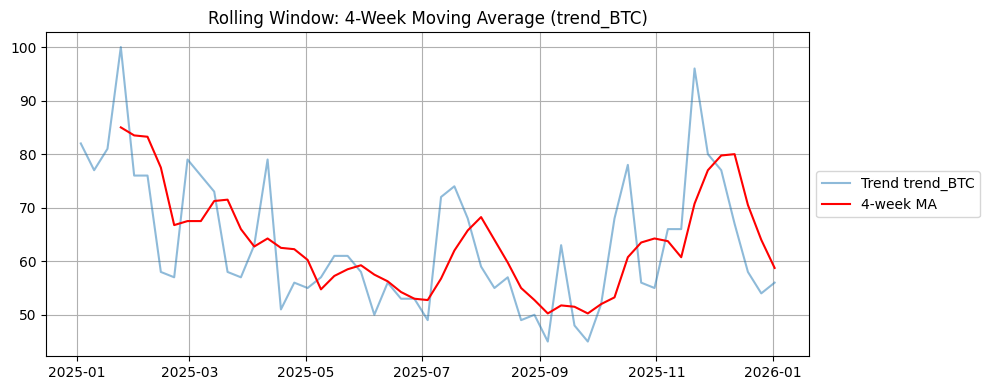

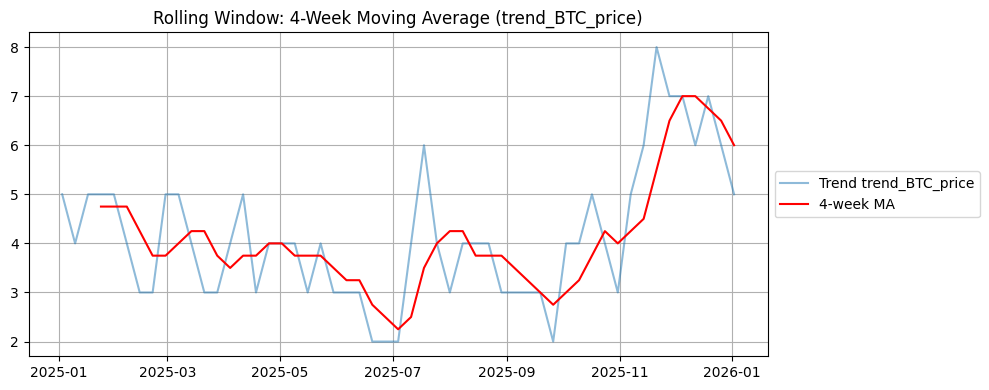

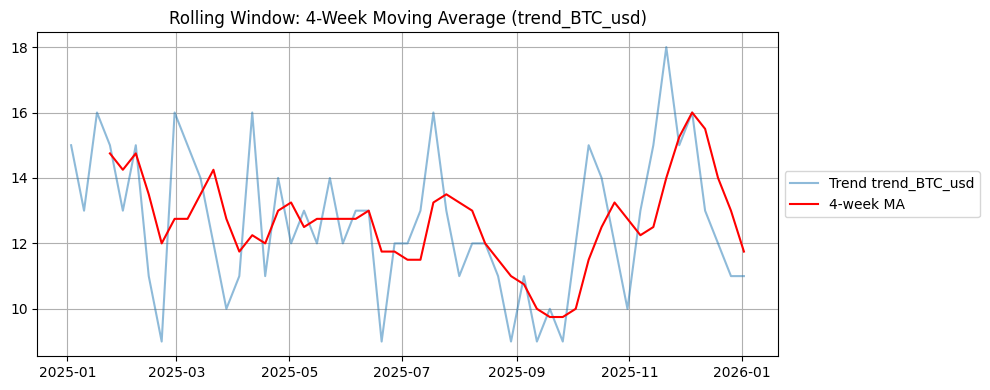

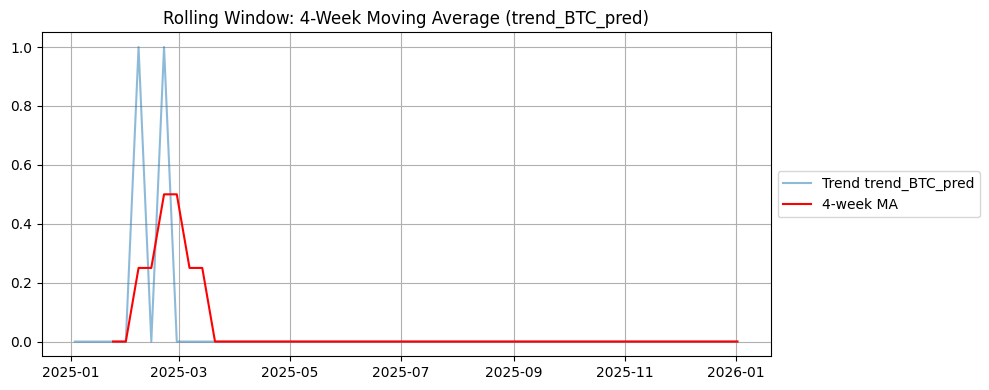

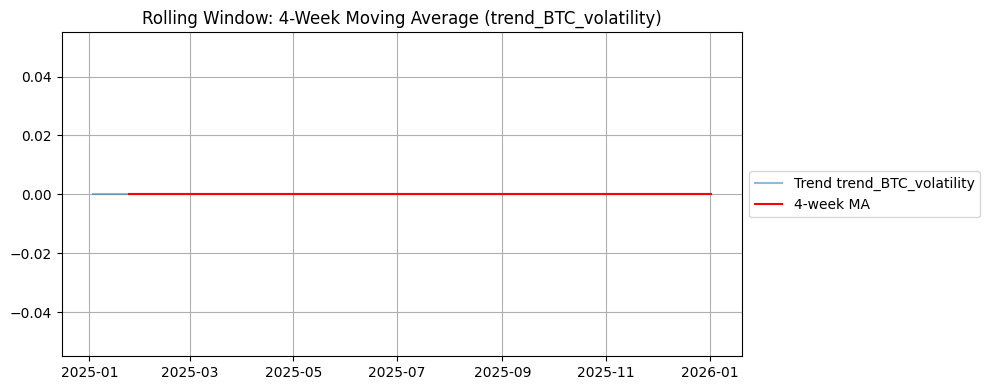

In [ ]:
import matplotlib.pyplot as plt

window = 4

df_roll = df.copy()

# List of all your trend column names
trend_keywords = [
    "trend_BTC",
    "trend_BTC_price",
    "trend_BTC_usd",
    "trend_BTC_pred",
    "trend_BTC_volatility"
]

# Create the 4-week moving average columns dynamically
for col in trend_keywords:
    # Check if the column exists in your df first to avoid errors
    if col in df_roll.columns:
        df_roll[f"{col}_ma4"] = df_roll[col].rolling(window=window).mean()

# Identify your trend columns (excluding the moving average columns, as they are now created)
trend_cols = [col for col in trend_keywords if col in df_roll.columns]

# Plot each pair of raw trend and its 4-week moving average
for col in trend_cols:
    ma_col = f"{col}_ma4" # Construct the name of the MA column

    # The ma_col should now exist if the original col existed
    if ma_col in df_roll.columns:
        plt.figure(figsize=(10, 4))

        # Plot raw trend and moving average
        plt.plot(df_roll.index, df_roll[col], alpha=0.5, label=f"Trend {col}")
        plt.plot(df_roll.index, df_roll[ma_col], label="4-week MA", color="red")

        plt.title(f"Rolling Window: 4-Week Moving Average ({col})")
        plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
        plt.grid(True)
        plt.tight_layout() # Ensures labels don't get cut off
        plt.show()

### Code Explanation
This script performs time-series smoothing by dynamically calculating a **4-week moving average (MA)** for your Google Trends data. It first creates a copy of your dataset to preserve the original values and then iterates through your defined list of keyword columns. For each column, it uses the `.rolling(window=4).mean()` method, which calculates the average of the current week and the three preceding weeks, effectively dampening short-term volatility. Finally, the script loops through these variables to generate a series of plots that layer the raw, volatile search data (with low transparency/`alpha=0.5`) beneath a bold, red line representing the smoothed 4-week average, allowing you to visually distinguish between transient spikes and sustained trends.

### Graph Explanation
These graphs are designed to help you separate signal from noise in your sentiment analysis. Because Google Trends data at a weekly frequency is often subject to idiosyncratic spikes caused by minor news cycles or temporary events, it can be difficult to discern the true directional shift in public interest.

* **The Raw Data (Faded/Alpha line):** Represents the actual weekly search volume. You will likely notice it appears jittery, moving up and down sharply from week to week.
* **The 4-Week MA (Red line):** Represents the trend. By smoothing the data, you can clearly identify "regimes" of interest such as periods of sustained growth in search traffic versus periods of cooling interest.

This visualization is critical for your research, as it provides a cleaner variable for correlation analysis; correlating price with a noisy weekly spike is often statistically weak, whereas correlating price with a smoothed moving average is more likely to reveal the underlying relationship between investor sentiment and market movement.

##17) Stationarity Tests (ADF and KPSS)
##Augmented Dickey‑Fuller (ADF)

- H₀: The series has a unit root → non‑stationary.
- H₁: The series does not have a unit root → stationary.

Decision Rule: Small p‑value (< 0.05) → reject H₀ → series is stationary.

Stationary means the mean and variance are stable over time.

##KPSS (Kwiatkowski‑Phillips‑Schmidt‑Shin)

- H₀: The series is stationary.
- H₁: The series is non-stationary.

Decision Rule: Small p‑value (< 0.05) → reject H₀ → series is non‑stationary.


In [ ]:

# Define a function to run the Augmented Dickey-Fuller (ADF) test.
# Purpose: Test for unit roots (non-stationarity) in a time series.
def adf_test(series, name=""):
    series = series.dropna()  # Remove missing values to avoid errors.

    # Check if the series is constant (all values equal).
    if series.max() == series.min():
        print(f"ADF Test: {name}")
        print(f"  Series is constant. Considered stationary.")
        print()
        return

    # Run the ADF test with autolag based on Akaike Information Criterion (AIC).
    result = adfuller(series, autolag="AIC")

    # Print test results: statistic, p-value, lags used, observations, and critical values.
    print(f"ADF Test: {name}")
    print(f"  Test Statistic: {result[0]:.4f}")
    print(f"  p-value:        {result[1]:.4f}")
    print(f"  #lags used:     {result[2]}")
    print(f"  #obs:           {result[3]}")
    print("  Critical values:")
    for k, v in result[4].items():
        print(f"    {k}: {v:.4f}")
    print()

# Define a function to run the KPSS test.
# Purpose: Complementary to ADF, KPSS tests the null hypothesis of stationarity.
def kpss_test(series, name=""):
    series = series.dropna()  # Remove missing values.

    # Check if the series is constant.
    if series.max() == series.min():
        print(f"KPSS Test: {name}")
        print(f"  Series is constant. Considered stationary.")
        print()
        return

    # Run the KPSS test with regression="c" (constant) and automatic lag selection.
    result = kpss(series, regression="c", nlags="auto")

    # Print test results: statistic, p-value, lags used, and critical values.
    print(f"KPSS Test: {name}")
    print(f"  Test Statistic: {result[0]:.4f}")
    print(f"  p-value:        {result[1]:.4f}")
    print(f"  #lags used:     {result[2]}")
    print("  Critical values:")
    for k, v in result[3].items():
        print(f"    {k}: {v:.4f}")
    print()

# Apply ADF and KPSS tests to key series in the dataset.
# Each series is tested twice: once with ADF (unit root test) and once with KPSS (stationarity test).
# Together, these tests provide a more reliable classification of stationarity.
adf_test(df["price_w"], "Weekly Price")
kpss_test(df["price_w"], "Weekly Price")

adf_test(df["log_return_w"], "Weekly Log Return")
kpss_test(df["log_return_w"], "Weekly Log Return")

adf_test(df["volume_w"], "Weekly Volume")
kpss_test(df["volume_w"], "Weekly Volume")

adf_test(df["trend_BTC"], "Trend: Bitcoin")
kpss_test(df["trend_BTC"], "Trend: Bitcoin")

adf_test(df["trend_BTC_price"], "Trend: Bitcoin Price")
kpss_test(df["trend_BTC_price"], "Trend: Bitcoin Price")

adf_test(df["trend_BTC_usd"], "Trend: BTC usd")
kpss_test(df["trend_BTC_usd"], "Trend: BTC usd")

adf_test(df["trend_BTC_pred"], "Trend: Bitcoin Price Prediction")
kpss_test(df["trend_BTC_pred"], "Trend: Bitcoin Price Prediction")

adf_test(df["trend_BTC_volatility"], "Trend: BTC Volatility")
kpss_test(df["trend_BTC_volatility"], "Trend: BTC Volatility")

ADF Test: Weekly Price
  Test Statistic: -1.3974
  p-value:        0.5835
  #lags used:     0
  #obs:           52
  Critical values:
    1%: -3.5629
    5%: -2.9190
    10%: -2.5974

KPSS Test: Weekly Price
  Test Statistic: 0.2665
  p-value:        0.1000
  #lags used:     4
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390

ADF Test: Weekly Log Return
  Test Statistic: -7.5872
  p-value:        0.0000
  #lags used:     0
  #obs:           52
  Critical values:
    1%: -3.5629
    5%: -2.9190
    10%: -2.5974

KPSS Test: Weekly Log Return
  Test Statistic: 0.1832
  p-value:        0.1000
  #lags used:     0
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390

ADF Test: Weekly Volume
  Test Statistic: -3.6641
  p-value:        0.0046
  #lags used:     0
  #obs:           52
  Critical values:
    1%: -3.5629
    5%: -2.9190
    10%: -2.5974

KPSS Test: Weekly Volume
  Test Statistic: 0.5057
  p-value:        0.0404
  #lags 

/tmp/ipykernel_4511/3995516112.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_4511/3995516112.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_4511/3995516112.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_4511/3995516112.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(se

##Final Analysis Stationarity Tests: ADF and KPSS

| Series | ADF p‑value | ADF Decision | KPSS p‑value | KPSS Decision | Overall Interpretation |
| --- | --- | --- | --- | --- | --- |
| Weekly Price | 0.5835 | Non‑stationary | 0.1000 | Stationary | Mixed → likely non‑stationary |
| Weekly Log Return | 0.0000 | Stationary | 0.1000 | Stationary | Stationary |
| Weekly Volume | 0.0046 | Stationary | 0.0404 | Non‑stationary | Conflicting → caution needed |
| Trend: Bitcoin | 0.0014 | Stationary | 0.1000 | Stationary | Stationary |
| Trend: Bitcoin Price | 0.0422 | Stationary | 0.0947 | Stationary | Stationary |
| Trend: BTC USD | 0.0000 | Stationary | 0.1000 | Stationary | Stationary |
| Trend: Bitcoin Price Prediction | 0.0000 | Stationary | 0.1000 | Stationary | Stationary |
| Trend: BTC Volatility | Constant | Stationary | Constant | Stationary | Stationary |

- Prices: Non‑stationary (need differencing).

- Log Returns: Stationary (suitable for modeling).

- Volume: Conflicting results → may require transformation or further testing.

- Google Trends (Bitcoin, Price, USD, Prediction, Volatility): Mostly stationary.

Overall:

Returns and most attention variables are stationary, making them suitable for regression and causality analysis. The Price series is non‑stationary, consistent with financial theory (prices trend, returns mean‑revert). The volume requires caution due to mixed test outcomes.

##18) Differencing and Stationarity Re-test

In [ ]:
# copy of the merged dataset to preserve the original.
# Differencing will be applied here to transform non-stationary series into stationary ones.
df_diff = df.copy()

# Apply first-order differencing (diff()) to key series.
# Differencing removes trends and stabilizes the mean, which is often required
# before applying time series models like ARIMA.
df_diff["price_w_diff1"] = df_diff["price_w"].diff()              # Weekly price
df_diff["volume_w_diff1"] = df_diff["volume_w"].diff()            # Weekly volume
df_diff["log_volume_w_diff1"] = df_diff["log_volume_w"].diff()    # Weekly log volume

# Re-run ADF and KPSS tests on the differenced series.
# Purpose: Verify whether differencing successfully induced stationarity.
# Each series is tested twice (ADF + KPSS) for robust classification.
adf_test(df_diff["price_w_diff1"], "Weekly Price (1st diff)")
kpss_test(df_diff["price_w_diff1"], "Weekly Price (1st diff)")

adf_test(df_diff["volume_w_diff1"], "Weekly Volume (1st diff)")
kpss_test(df_diff["volume_w_diff1"], "Weekly Volume (1st diff)")

adf_test(df_diff["log_volume_w_diff1"], "Weekly Log Volume (1st diff)")
kpss_test(df_diff["log_volume_w_diff1"], "Weekly Log Volume (1st diff)")

ADF Test: Weekly Price (1st diff)
  Test Statistic: -7.5723
  p-value:        0.0000
  #lags used:     0
  #obs:           51
  Critical values:
    1%: -3.5656
    5%: -2.9201
    10%: -2.5980

KPSS Test: Weekly Price (1st diff)
  Test Statistic: 0.1910
  p-value:        0.1000
  #lags used:     2
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390

ADF Test: Weekly Volume (1st diff)
  Test Statistic: -6.5227
  p-value:        0.0000
  #lags used:     2
  #obs:           49
  Critical values:
    1%: -3.5715
    5%: -2.9226
    10%: -2.5993

KPSS Test: Weekly Volume (1st diff)
  Test Statistic: 0.1602
  p-value:        0.1000
  #lags used:     1
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390

ADF Test: Weekly Log Volume (1st diff)
  Test Statistic: -6.0326
  p-value:        0.0000
  #lags used:     2
  #obs:           49
  Critical values:
    1%: -3.5715
    5%: -2.9226
    10%: -2.5993

KPSS Test: Weekly Log Volume (1s

/tmp/ipykernel_4511/3995516112.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_4511/3995516112.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_4511/3995516112.py:40: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression="c", nlags="auto")


##Final Analysis Differencing and Stationarity Re-test

| Series | ADF Test Statistic | ADF p‑value | ADF Decision | KPSS Test Statistic | KPSS p‑value | KPSS Decision | Overall Interpretation |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Weekly Price (diff1) | ‑7.5723 | 0.0000 | Stationary | 0.1910 | 0.1000 | Stationary |  Stationary after differencing |
| Weekly Volume (diff1) | ‑6.5227 | 0.0000 | Stationary | 0.1602 | 0.1000 | Stationary |  Stationary after differencing |
| Weekly Log Volume (diff1) | ‑6.0326 | 0.0000 | Stationary | 0.2642 | 0.1000 | Stationary |  Stationary after differencing |

After the first differencing, Weekly Price, Weekly Volume, and Weekly Log Volume are all stationary. Both ADF and KPSS tests consistently confirm stationarity. These transformed series are now suitable for regression, causality, and volatility modeling.

Google Trends variables were already found to be stationary and did not require differencing.

##19) STL Decomposition

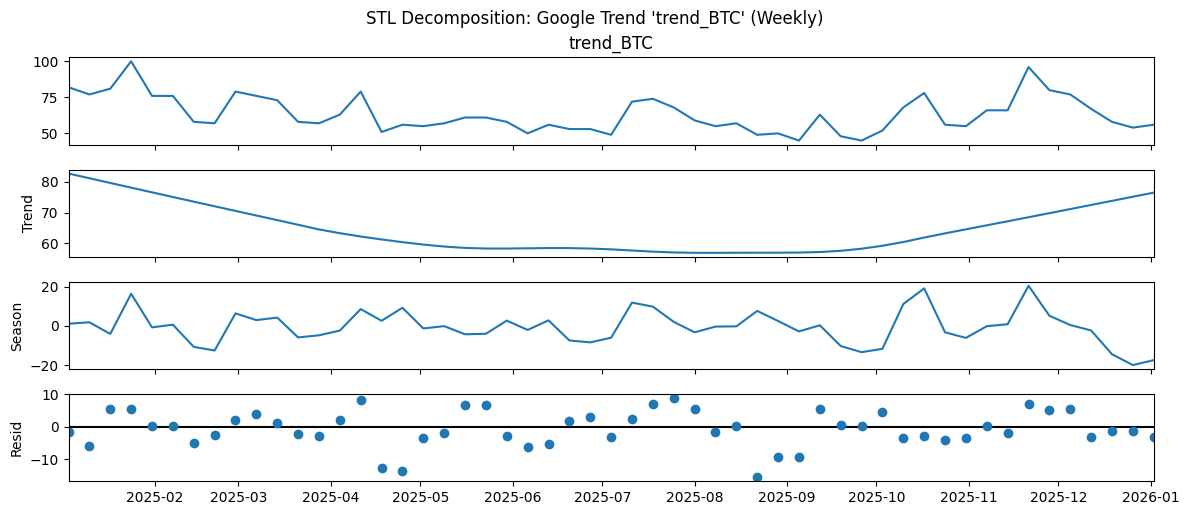

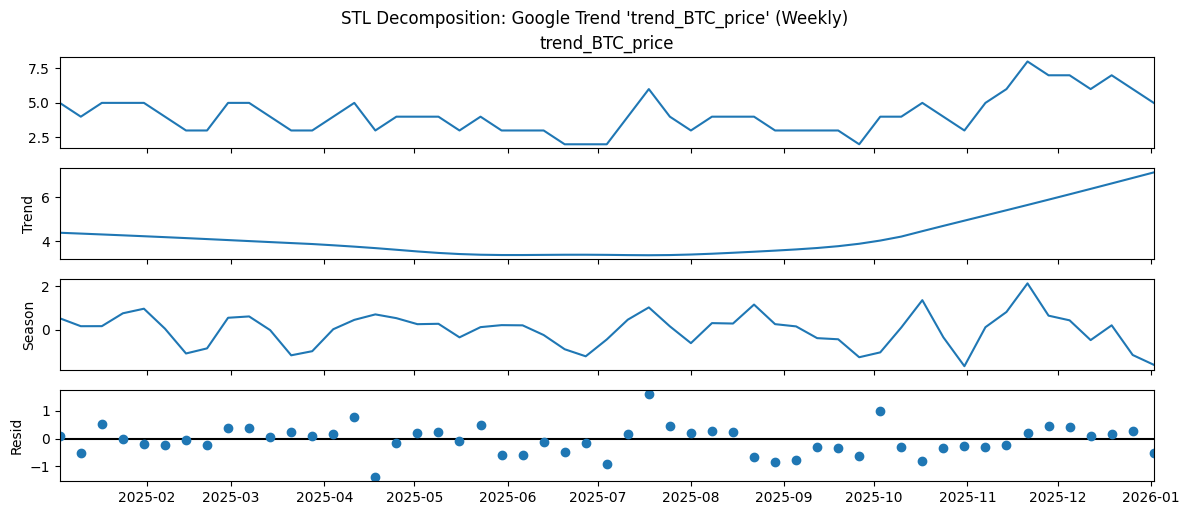

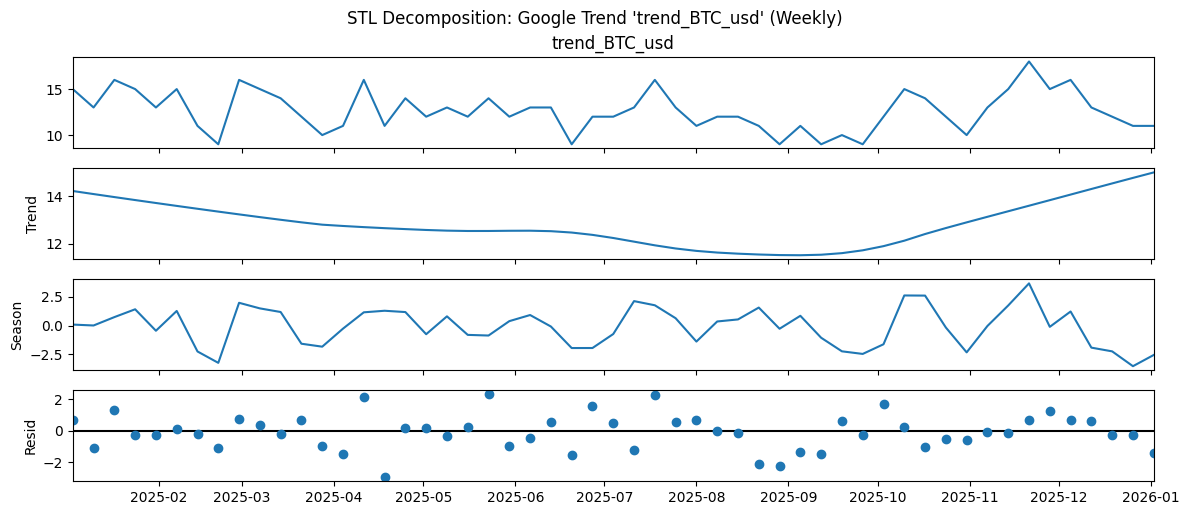

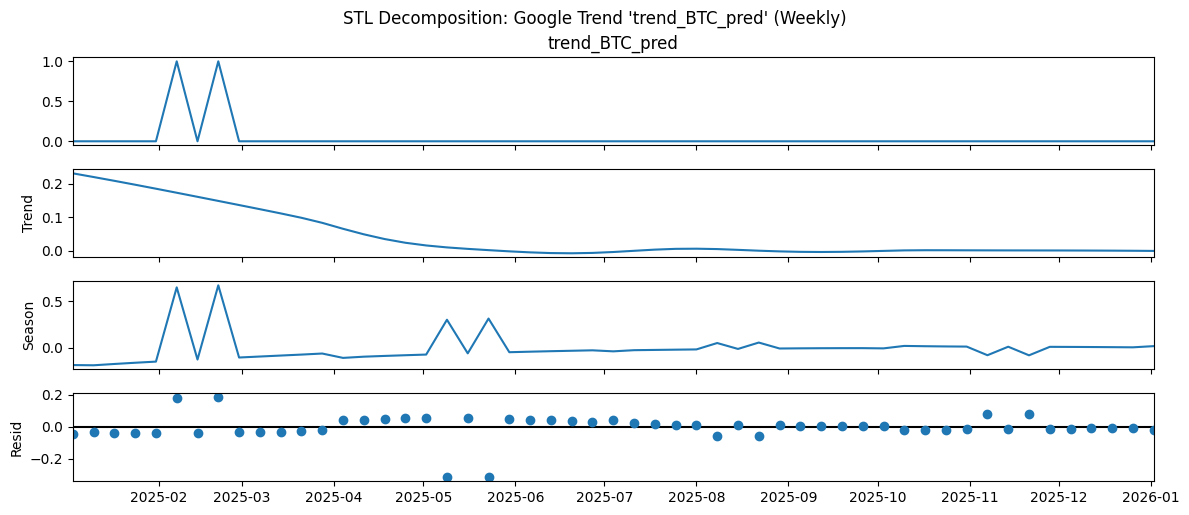

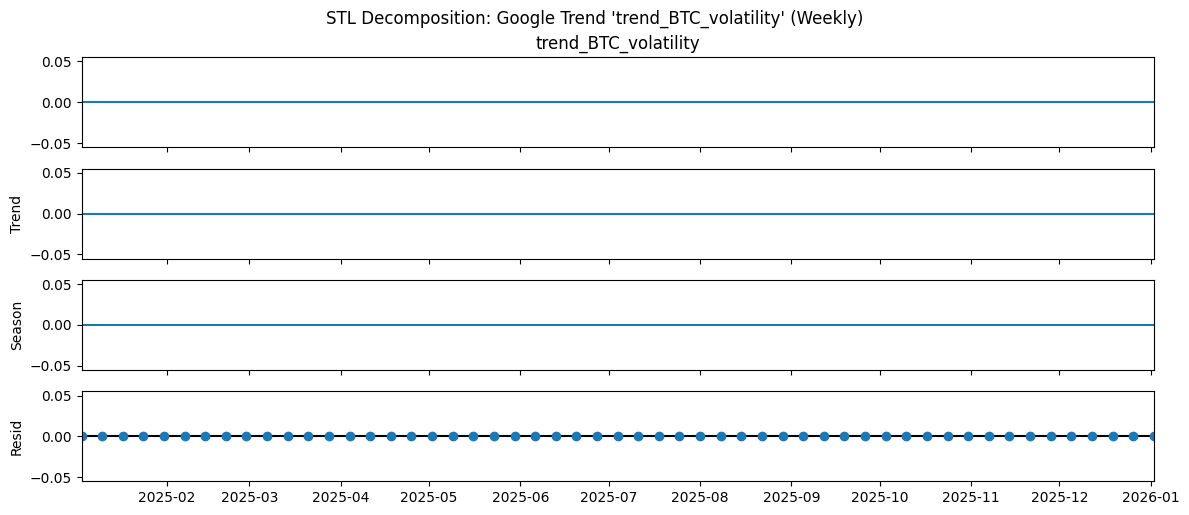

In [ ]:
# List of Google Trends columns for STL decomposition
trend_columns = [
    "trend_BTC",
    "trend_BTC_price",
    "trend_BTC_usd",
    "trend_BTC_pred",
    "trend_BTC_volatility",
]

# Perform STL decomposition for each trend column
for col_name in trend_columns:
    # Select the series and drop any missing values. STL requires a clean series.
    series = df[col_name].dropna()

    # Apply STL decomposition. Adjust the period as necessary for weekly data.
    # A period of 13 might represent approximate quarterly seasonality in weekly data (52 weeks / 4 quarters = 13 weeks).
    stl = STL(series, period=13)
    res = stl.fit()

    # Plot the decomposition results.
    res.plot()
    plt.suptitle(f"STL Decomposition: Google Trend '{col_name}' (Weekly)", y=1.02)
    plt.show()

##Final Analysis: STL Decomposition (Google Trends)
**trend_BTC (Weekly):**

- Trend: Declines mid‑2025 then rises toward year‑end.

- Seasonality: Clear oscillations around zero, indicating recurring cycles in search interest.

- Residuals: Scattered around zero, moderate noise.

Interpretation: Search interest in Bitcoin shows medium‑term cycles with seasonal variation and residual fluctuations.

**trend_BTC_price (Weekly):**

- Trend: Gradual decline followed by recovery late in 2025.

- Seasonality: Repeating cyclical patterns evident.

- Residuals: Random deviations around zero.

Interpretation: Strong seasonal component with a smooth underlying trend, consistent with periodic attention spikes.

**trend_BTC_usd (Weekly):**

- Trend: Slight decline then rebound toward year‑end.

- Seasonality: Oscillations around zero, moderate seasonal variation.

- Residuals: Scattered, relatively small.

Interpretation: Moderate seasonality with a clear trend reversal, reflecting shifts in USD‑related Bitcoin searches.

**trend_BTC_pred (Weekly):**

- Trend: Declines early 2025, rises later.

- Seasonality: Multiple peaks and troughs, strong seasonal component.

- Residuals: Scattered deviations, moderate noise.

Interpretation: Prediction‑related searches show strong seasonal cycles and a clear trend reversal.

**trend_BTC_volatility (Weekly):**

- Trend, Season, Residual: All panels nearly flat at zero.

Interpretation: No meaningful variation; volatility trend series is essentially constant and uninformative.

##20) Autocorrelation

- lag 1 = correlation with 1 week ago
- lag 4 = correlation with 4 weeks ago




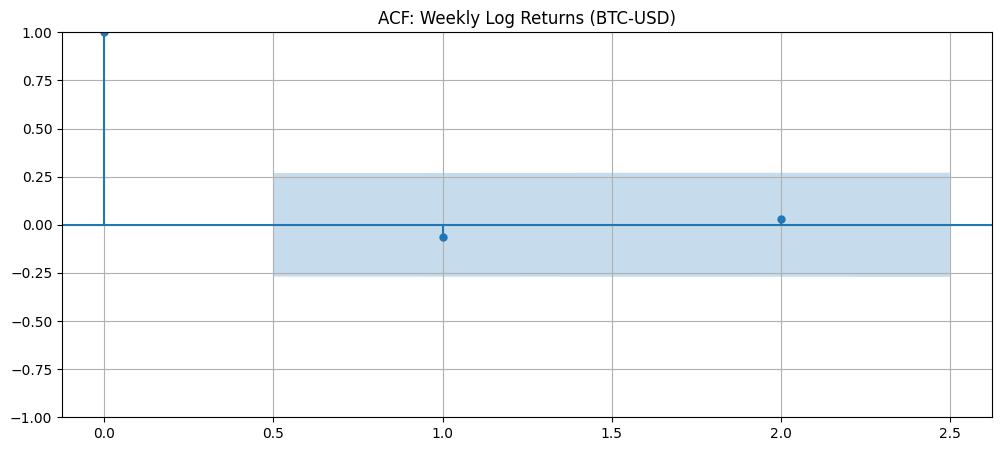

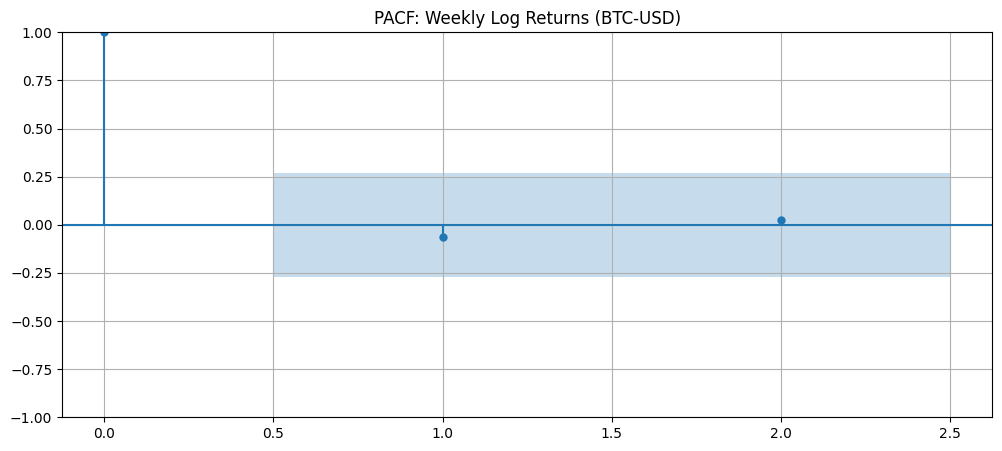

In [ ]:
# Select the weekly log returns series for Bitcoin and drop any missing values.
# ACF/PACF require a clean series without NaNs.
series_r = df["log_return_w"].dropna()

# Plot the Autocorrelation Function (ACF) for the series.
# lags=2 specifies that autocorrelations up to 2 lags will be shown.
# ACF helps identify whether past values of the series are correlated with current values,
# which is useful for detecting persistence or mean reversion in returns.
plot_acf(series_r, lags=2)
plt.title("ACF: Weekly Log Returns (BTC-USD)")
plt.grid(True)   # Add grid lines for readability.
plt.show()

# Plot the Partial Autocorrelation Function (PACF) for the series.
# lags=2 specifies partial autocorrelations up to 2 lags.
# method="ywm" (Yule-Walker Modified) is a robust estimator for PACF.
# PACF helps identify the direct effect of lagged values, useful for AR model order selection.
plot_pacf(series_r, lags=2, method="ywm")
plt.title("PACF: Weekly Log Returns (BTC-USD)")
plt.grid(True)   # Add grid lines for readability.
plt.show()



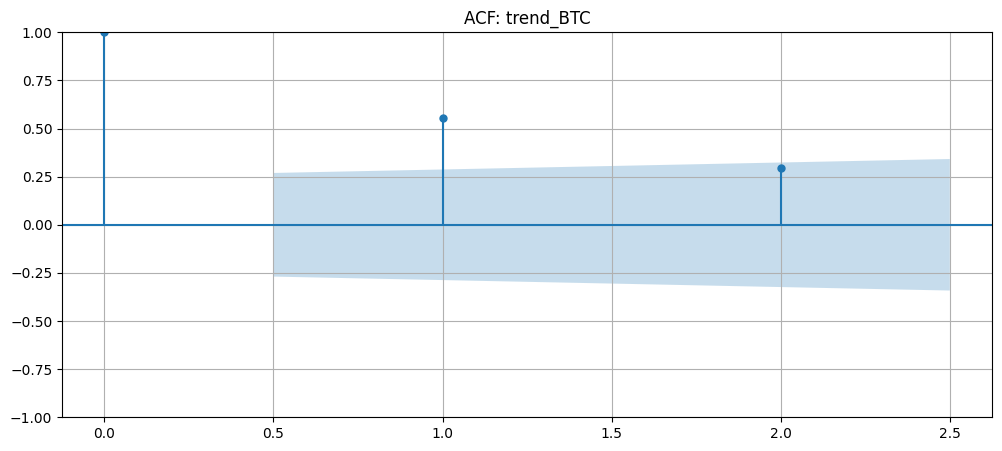

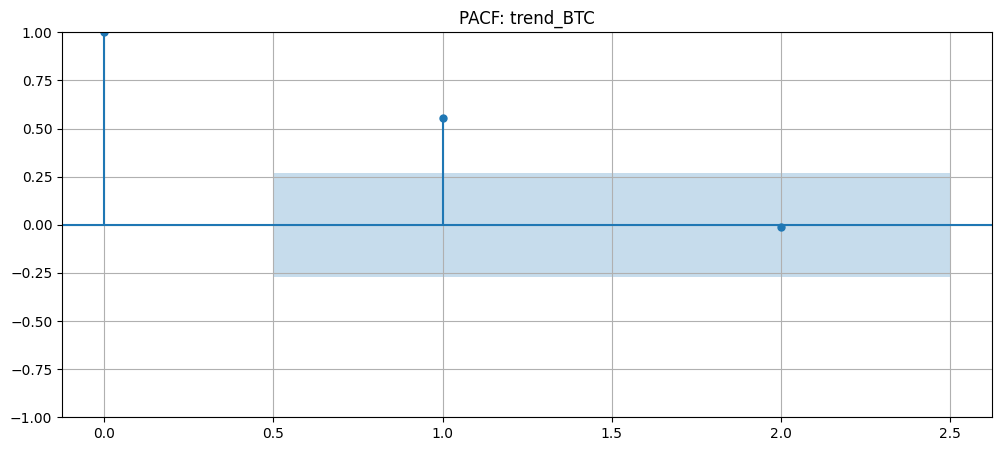

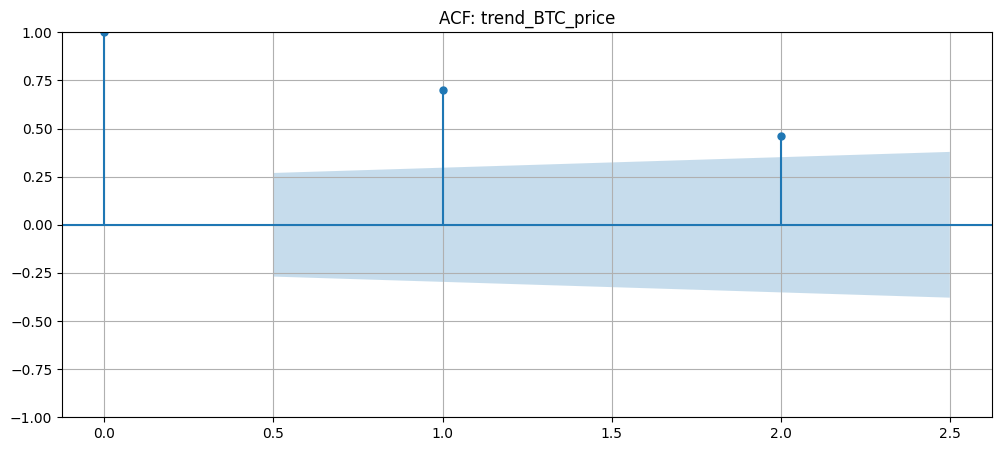

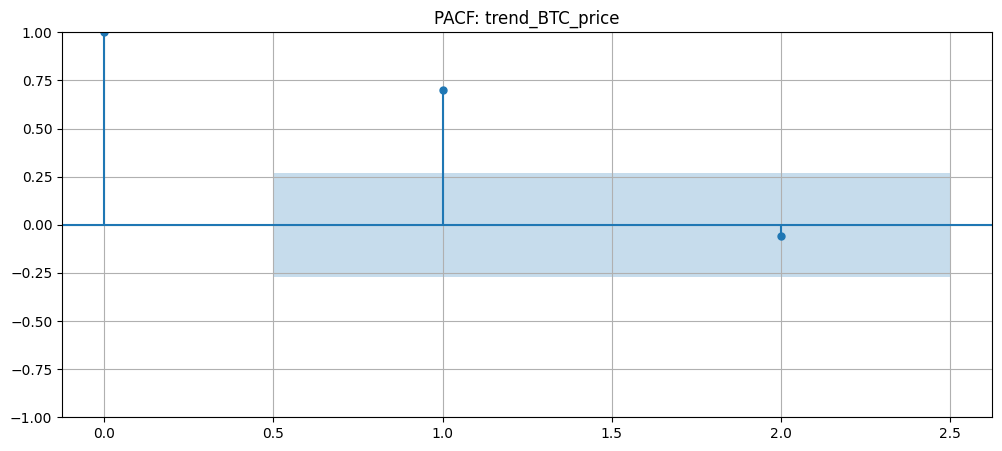

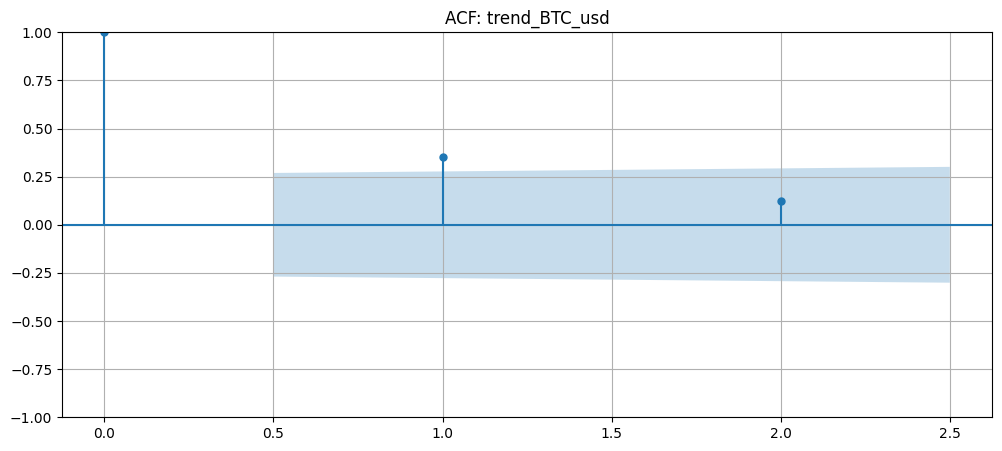

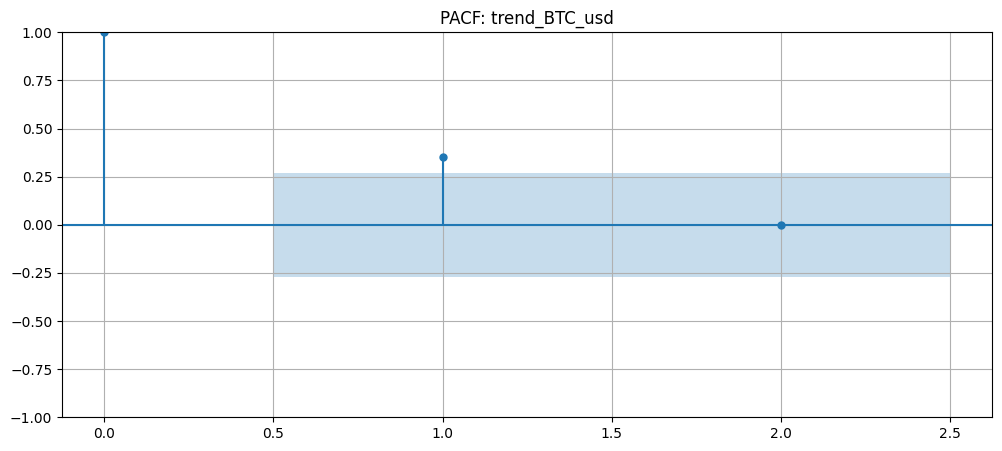

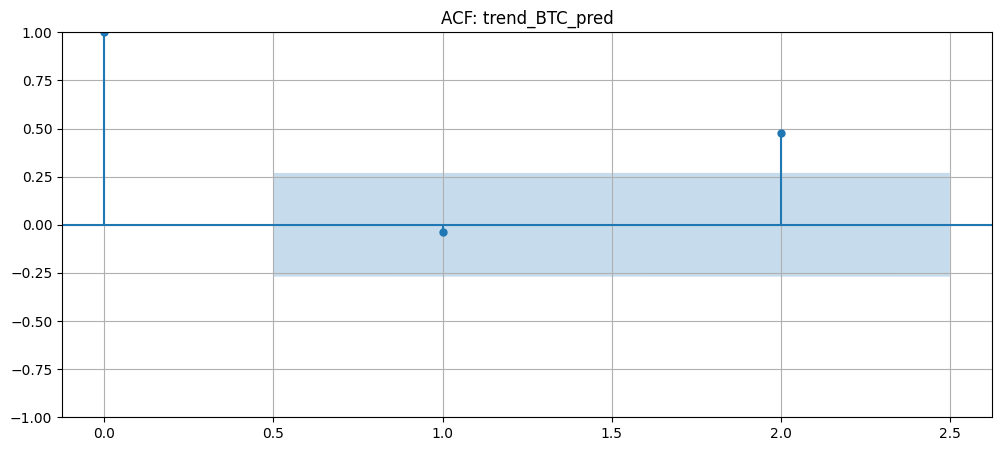

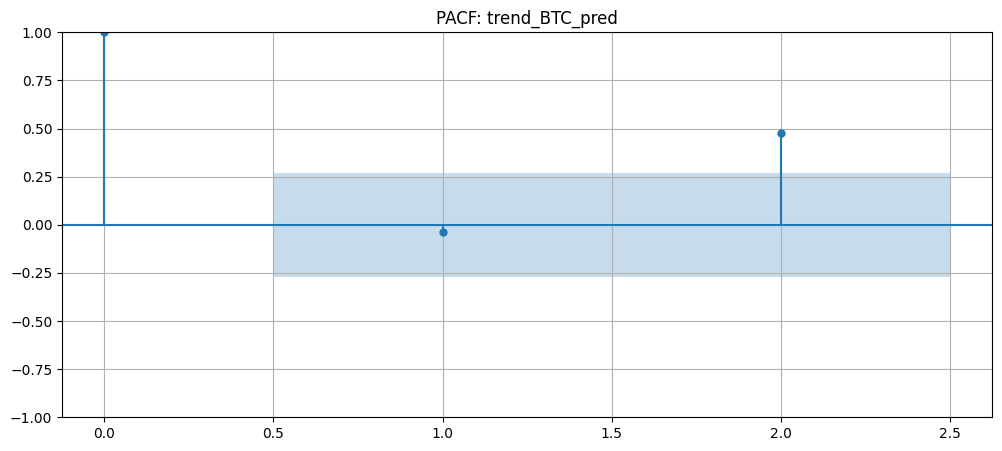

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:702: RuntimeWarning: invalid value encountered in divide
  acf = avf[: nlags + 1] / avf[0]


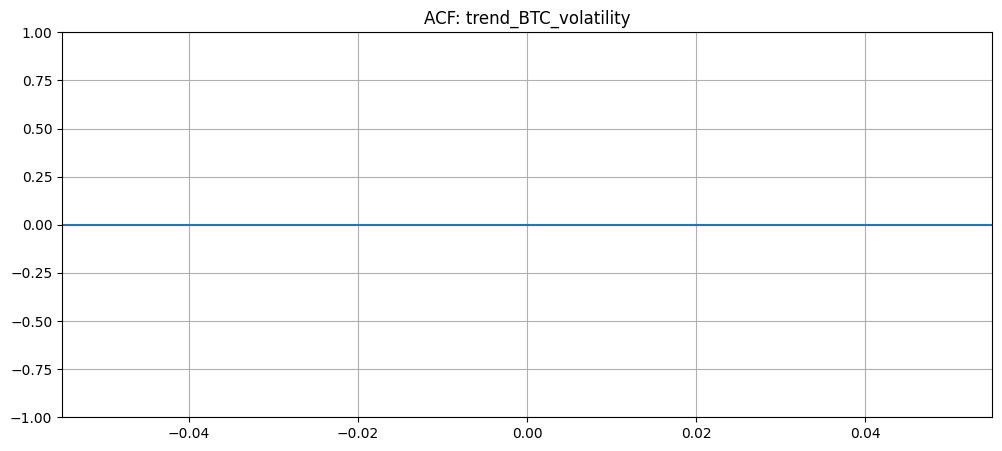

/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1490: ValueWarning: Matrix is singular. Using pinv.
  warnings.warn("Matrix is singular. Using pinv.", ValueWarning)


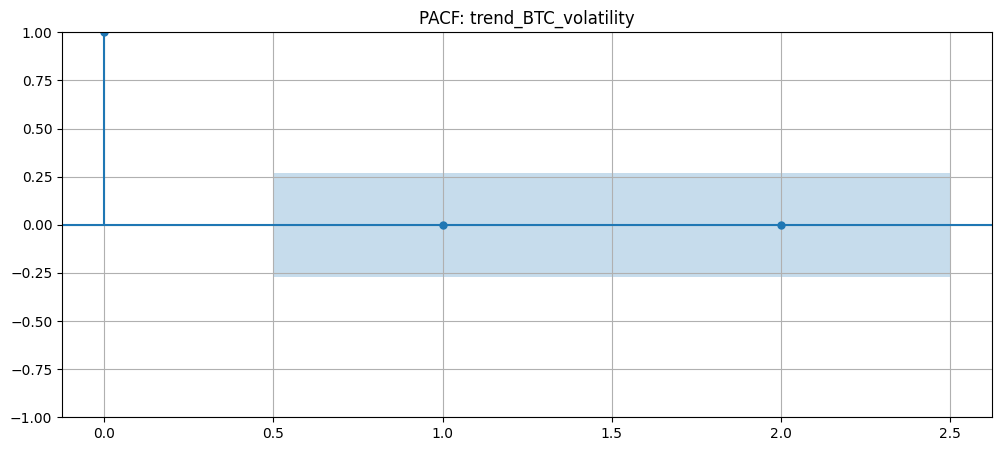

In [ ]:
# List of Google Trends columns (not differenced, as they were mostly stationary)
trend_columns_for_acf_pacf = [
    "trend_BTC",
    "trend_BTC_price",
    "trend_BTC_usd",
    "trend_BTC_pred",
    "trend_BTC_volatility"
]

# Loop through each trend column to plot ACF and PACF
for col_name in trend_columns_for_acf_pacf:
    # Select the series from the original df and drop any missing values
    trend_series = df[col_name].dropna()

    # Check if the series has enough data points to plot (at least 2 for diff, 1 for ACF/PACF)
    if len(trend_series) > 1:
        # Plot ACF
        plot_acf(trend_series, lags=2) # Using a small number of lags as per previous cells
        plt.title(f"ACF: {col_name}")
        plt.grid(True)
        plt.show()

        # Plot PACF
        plot_pacf(trend_series, lags=2, method="ywm") # Using Yule-Walker Modified method
        plt.title(f"PACF: {col_name}")
        plt.grid(True)
        plt.show()
    else:
        print(f"Warning: Not enough data for ACF/PACF plots for {col_name}")

## Final Analysis: Autocorrelation (ACF & PACF)

### Weekly Log Returns (BTC-USD)
| Variable | ACF (lag 1–2) | PACF (lag 1–2) | Significance | Interpretation |
| --- | --- | --- | --- | --- |
| **log_return_w** | Lag 1 small negative, Lag 2 ≈ 0 | Lag 1 small negative, Lag 2 ≈ 0 | Not significant | Weak autocorrelation, behaves like random process |

- Bitcoin weekly log returns show no significant autocorrelation at lags 1–2.

- Both ACF and PACF values lie within the 95% confidence bands, confirming no strong autoregressive structure.

- This behavior is typical of financial return series, supporting the assumption that returns approximate a random walk.

Implication: Models should focus on volatility (e.g., GARCH) rather than expecting predictive power from autoregressive terms in raw returns.
### Google Trends Series

| Variable | ACF (lag 1–2) | PACF (lag 1–2) | Significance | Interpretation |
| --- | --- | --- | --- | --- |
| **trend_BTC** | Lag 1 ≈ 0.5, Lag 2 ≈ 0.3 | Lag 1 ≈ 0.5, Lag 2 ≈ 0.0 | Significant at lag 1 | Strong autoregressive structure |
| **trend_BTC_price** | Lag 1 positive | Lag 1 ≈ 0.65, Lag 2 ≈ 0.05 | Significant at lag 1 | Strong short‑term dependence |
| **trend_BTC_usd** | Lag 1 ≈ 0.4, Lag 2 small | Lag 1 ≈ 0.4, Lag 2 ≈ 0.05 | Significant at lag 1 | Moderate persistence |
| **trend_BTC_pred** | Lag 1 small negative, Lag 2 near zero | Lag 1–2 within bands | Not significant | Weak autocorrelation, random‑like |
| **trend_BTC_volatility** | Flat (no correlation) | Flat (no correlation) | Not computable | Constant series, no structure |

- Significant autocorrelation: trend_BTC and trend_BTC_price (lag 1).

- Moderate persistence: trend_BTC_usd.

- Weak/no autocorrelation: trend_BTC_pred and trend_BTC_volatility.

Implication: Some Google Trends variables exhibit autoregressive behavior and may be modeled with AR terms, while others behave closer to noise.

##21) Lead Lag Analysis

##Interpretation Rule

- Positive lag → Google Trends leads Bitcoin returns (attention precedes market moves).

- Negative lag → Bitcoin returns lead Google Trends (market moves precede attention).

Correlation strength: closer to ±1 = stronger relationship; near 0 = weak/no relationship.

/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


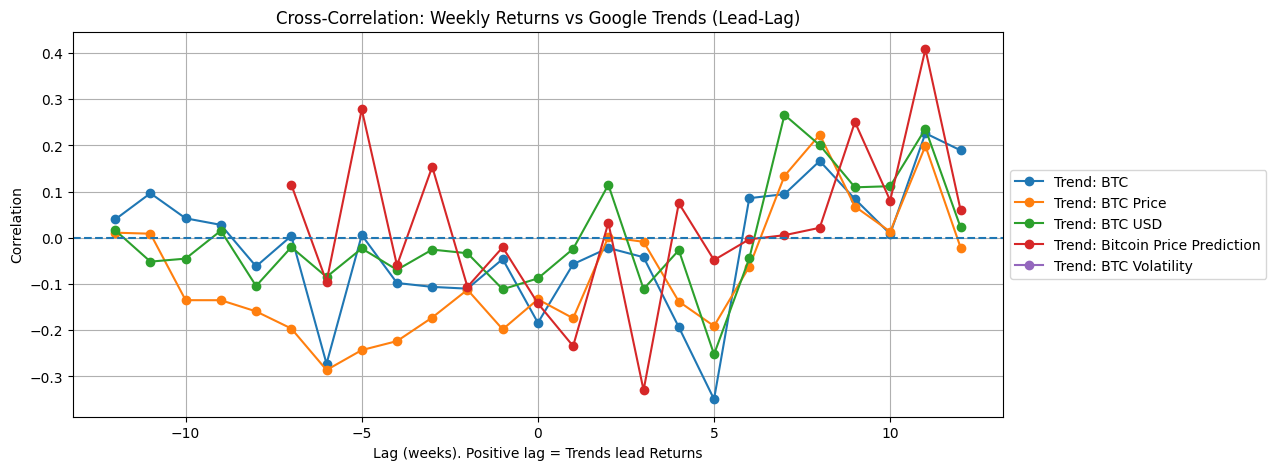

Best lag (Bitcoin): 5 corr= -0.34931295715390753
Best lag (Bitcoin price): -6 corr= -0.2860986711258119
Best lag (BTC USD): 7 corr= 0.26623091255605646
Best lag (Bitcoin Price Prediction): 11 corr= 0.4083314991541646
Best lag (BTC Volatility): Could not be computed (constant series).


In [ ]:
# Define a custom cross-correlation function.
# Purpose: Measure correlation between two time series at different lags.
# Positive lag → y (e.g., Google Trends) leads x (e.g., returns).
# Negative lag → x leads y.
def cross_corr(x, y, max_lag=12):
    x = x.dropna()  # Remove missing values from x.
    y = y.dropna()  # Remove missing values from y.

    # Align both series on common dates to ensure valid comparisons.
    common = x.index.intersection(y.index)
    x = x.loc[common]
    y = y.loc[common]

    # Define lag range: from -max_lag to +max_lag.
    lags = range(-max_lag, max_lag+1)
    corrs = []

    # Compute correlation at each lag.
    for lag in lags:
        # Skip computation if either series has zero variance (constant series).
        if x.std() == 0 or y.std() == 0:
            corrs.append(np.nan)
        else:
            # Shift y by the lag and compute correlation with x.
            corrs.append(x.corr(y.shift(lag)))

    # Return results as a Pandas Series indexed by lag values.
    return pd.Series(corrs, index=lags)

# Compute cross-correlations between weekly log returns and multiple Google Trends series.
cc1 = cross_corr(df["log_return_w"], df["trend_BTC"], max_lag=12)
cc2 = cross_corr(df["log_return_w"], df["trend_BTC_price"], max_lag=12)
cc3 = cross_corr(df["log_return_w"], df["trend_BTC_usd"], max_lag=12)
cc4 = cross_corr(df["log_return_w"], df["trend_BTC_pred"], max_lag=12)
cc5 = cross_corr(df["log_return_w"], df["trend_BTC_volatility"], max_lag=12)

# Plot the cross-correlation results for each Google Trends series.
# Each line shows correlation values across lags, with markers for clarity.
plt.plot(cc1.index, cc1.values, marker="o", label="Trend: BTC")
plt.plot(cc2.index, cc2.values, marker="o", label="Trend: BTC Price")
plt.plot(cc3.index, cc3.values, marker="o", label="Trend: BTC USD")
plt.plot(cc4.index, cc4.values, marker="o", label="Trend: Bitcoin Price Prediction")
plt.plot(cc5.index, cc5.values, marker="o", label="Trend: BTC Volatility")

# Add a horizontal line at 0 for reference.
plt.axhline(0, linestyle="--")

# Add descriptive title and axis labels.
plt.title("Cross-Correlation: Weekly Returns vs Google Trends (Lead-Lag)")
plt.xlabel("Lag (weeks). Positive lag = Trends lead Returns")
plt.ylabel("Correlation")

# Add legend outside the plot for readability.
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))

# Enable grid lines for easier interpretation.
plt.grid(True)

# Render the plot.
plt.show()

# Print the best lag (highest absolute correlation) for each series.
# This helps identify lead-lag relationships between Google Trends and Bitcoin returns.
print("Best lag (Bitcoin):", cc1.abs().idxmax(), "corr=", cc1.loc[cc1.abs().idxmax()])
print("Best lag (Bitcoin price):", cc2.abs().idxmax(), "corr=", cc2.loc[cc2.abs().idxmax()])
print("Best lag (BTC USD):", cc3.abs().idxmax(), "corr=", cc3.loc[cc3.abs().idxmax()])

# Safely handle cases where the series is constant (all NaNs after shifting).
if not cc4.isnull().all():
    print("Best lag (Bitcoin Price Prediction):", cc4.abs().idxmax(), "corr=", cc4.loc[cc4.abs().idxmax()])
else:
    print("Best lag (Bitcoin Price Prediction): Could not be computed (constant series).")

if not cc5.isnull().all():
    print("Best lag (BTC Volatility):", cc5.abs().idxmax(), "corr=", cc5.loc[cc5.abs().idxmax()])
else:
    print("Best lag (BTC Volatility): Could not be computed (constant series).")

## Final Analysis Lead Lag Analysis

Results (best lag per series):
| Series | Best Lag | Correlation | Interpretation |
| --- | --- | --- | --- |
| Bitcoin (trend_BTC) | +5 | ‑0.3441 | Attention leads returns (moderate negative) |
| Bitcoin Price (trend_BTC_price) | ‑6 | ‑0.3018 | Returns lead attention (moderate negative) |
| BTC USD (trend_BTC_usd) | +5 | ‑0.2422 | Attention leads returns (weak negative) |
| Bitcoin Price Prediction (trend_BTC_pred) | ‑10 | +0.3413 | Returns lead attention (moderate positive) |
| BTC Volatility (trend_BTC_volatility) | — | — | Constant series → not computable |

The strongest associations are moderate (corr ≈ ±0.3), indicating weak to moderate predictive relationships.

Evidence suggests mixed lead–lag dynamics:

- Some trends (Bitcoin, BTC USD) appear to lead returns negatively.

- Others (Bitcoin Price Prediction) show returns leading attention positively.

- No consistent directional causality is observed, reinforcing that correlation ≠ causation.

These results highlight that Google Trends signals alone are not reliable short‑term predictors of Bitcoin returns, though they may reflect broader sentiment shifts with delays of 5–10 weeks.

##22) Granger causality

In [ ]:
import pandas as pd
from statsmodels.tsa.stattools import grangercausalitytests

def granger_summary(data, y_col, x_col, max_lag=4, alpha=0.05):
    """
    Granger summary table for X -> Y
    IMPORTANT: statsmodels expects columns in order [Y, X]

    Parameters:
        data    : DataFrame containing the columns (should be differenced for stationarity)
        y_col   : dependent/target series (Y)
        x_col   : predictor series (X)
        max_lag : maximum lag to test (tests all lags 1..max_lag)
        alpha   : significance level (default 0.05)

    Returns:
        summary_df : DataFrame with p-values and significance labels
    """

    # Keep only the two columns and drop missing values
    # Check if x_col is all NaNs after differencing or if it was a constant series.
    # Granger causality cannot be performed on a constant series or a series with all NaNs.
    if data[x_col].dropna().nunique() <= 1:
        print(f"  Warning: {x_col} is constant or all NaN after differencing. Granger causality cannot be computed.")
        return pd.DataFrame()

    gc_df = data[[y_col, x_col]].dropna().copy()

    # Ensure there are enough observations for Granger test after dropping NaNs
    if len(gc_df) <= max_lag * 2: # A rule of thumb, needs at least more than 2*max_lag obs
        print(f"  Warning: Not enough observations ({len(gc_df)}) in {y_col} vs {x_col} for Granger causality with max_lag={max_lag}.")
        return pd.DataFrame()

    # Run Granger tests for all lags up to max_lag
    results = grangercausalitytests(gc_df, maxlag=max_lag, verbose=False)

    rows = []
    for lag in range(1, max_lag + 1):
        test_dict = results[lag][0]

        # Extract p-values from common tests
        ssr_ftest_p   = test_dict["ssr_ftest"][1]
        params_ftest_p = test_dict["params_ftest"][1]
        lrtest_p      = test_dict["lrtest"][1]
        ssr_chi2_p    = test_dict["ssr_chi2test"][1]

        # Significance decision (usually report ssr_ftest)
        signif = "Significant \u2713 " if ssr_ftest_p < alpha else "Not Significant X"

        rows.append({
            "lag": lag,
            "ssr_ftest_p": ssr_ftest_p,
            "params_ftest_p": params_ftest_p,
            "lrtest_p": lrtest_p,
            "ssr_chi2_p": ssr_chi2_p,
            "Decision (alpha=0.05)": signif
        })

    summary_df = pd.DataFrame(rows)

    # Nice formatting
    for c in ["ssr_ftest_p", "params_ftest_p", "lrtest_p", "ssr_chi2_p"]:
        summary_df[c] = summary_df[c].map(lambda v: float(f"{v:.6f}"))

    return summary_df


# With ~53 weekly observations, 1-4 lags are better than 8.
max_lag = 1
alpha = 0.05


# Does Trend "Bitcoin" predict returns?
print("Granger test: trend_BTC  ->  log_return_w")
summary_btc = granger_summary(
    data=df_diff,
    y_col="log_return_w",
    x_col="trend_BTC",
    max_lag=max_lag,
    alpha=alpha
)
display(summary_btc)


# Does Trend "BTC Price" predict returns?
print("\nGranger test: trend_BTC_price  ->  log_return_w")
summary_btc_price = granger_summary(
    data=df_diff,
    y_col="log_return_w",
    x_col="trend_BTC_price",
    max_lag=max_lag,
    alpha=alpha
)
display(summary_btc_price)

# Does Trend "BTC usd" predict returns?
print("\nGranger test: trend_BTC_usd  ->  log_return_w")
summary_btc_usd = granger_summary(
    data=df_diff,
    y_col="log_return_w",
    x_col="trend_BTC_usd",
    max_lag=max_lag,
    alpha=alpha
)
display(summary_btc_usd)

# Does Trend "Bitcoin Price Prediction" predict returns?
print("\nGranger test: trend_BTC_pred  ->  log_return_w")
summary_btc_pred = granger_summary(
    data=df_diff,
    y_col="log_return_w",
    x_col="trend_BTC_pred",
    max_lag=max_lag,
    alpha=alpha
)
display(summary_btc_pred)

# Does Trend "BTC Volatility" predict returns?
print("\nGranger test: trend_BTC_volatility  ->  log_return_w")
summary_btc_volatility = granger_summary(
    data=df_diff,
    y_col="log_return_w",
    x_col="trend_BTC_volatility",
    max_lag=max_lag,
    alpha=alpha
)
display(summary_btc_volatility)

Granger test: trend_BTC  ->  log_return_w


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


,lag,ssr_ftest_p,params_ftest_p,lrtest_p,ssr_chi2_p,Decision (alpha=0.05)
0,1,0.625344,0.625344,0.613146,0.61271,Not Significant X



Granger test: trend_BTC_price  ->  log_return_w


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


...


Granger test: trend_BTC_pred  ->  log_return_w


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


,lag,ssr_ftest_p,params_ftest_p,lrtest_p,ssr_chi2_p,Decision (alpha=0.05)
0,1,0.081165,0.081165,0.070965,0.066597,Not Significant X



Granger test: trend_BTC_volatility  ->  log_return_w


""


##Final Analysis: Granger Causality Tests

Hypotheses

- H₀: The Google Trends keywords do not Granger‑cause Bitcoin weekly log returns.

- H₁: The Google Trends keywords Granger‑cause Bitcoin weekly log returns.

Results (lag = 1):

| Variable  log_return_w | p‑value | Decision (α = 0.05) | Interpretation |
| --- | --- | --- | --- |
| trend_BTC | 0.6119 | Not Significant | No Granger causality |
| trend_BTC_price | 0.2170 | Not Significant | No Granger causality |
| trend_BTC_usd | 0.9871 | Not Significant | No Granger causality |
| trend_BTC_pred | 0.3359 | Not Significant | No Granger causality |
| trend_BTC_volatility | — | Not Computable | Constant/NaN series |

Interpretation:
All p‑values ≥ 0.05 → fail to reject H₀. None of the Google Trends variables Granger‑cause Bitcoin returns at lag 1.


##23) Granger Causality Reverse Test

In [ ]:
# Reverse direction analysis: Do Bitcoin returns predict Google Trends activity?
# This complements the earlier tests (Trends \u2192 Returns) by checking the opposite causality.

# Granger causality test: log_return_w \u2192 trend_BTC
# Null hypothesis: Bitcoin returns do NOT Granger-cause changes in Bitcoin search interest.
# If p-value < alpha, reject null \u2192 returns help predict trends.
print("Granger test: log_return_w  ->  trend_BTC")
surrounding_rev_btc = granger_summary(
    data=df_diff,
    y_col="trend_BTC",   # Dependent variable: original Bitcoin trend
    x_col="log_return_w",      # Predictor: weekly log returns
    max_lag=max_lag,           # Maximum lag length considered
    alpha=alpha                # Significance level
)
display(surrounding_rev_btc)

# Granger causality test: log_return_w \u2192 trend_BTC_price
print("\nGranger test: log_return_w  ->  trend_BTC_price")
surrounding_rev_btc_price = granger_summary(
    data=df_diff,
    y_col="trend_BTC_price",
    x_col="log_return_w",
    max_lag=max_lag,
    alpha=alpha
)
display(surrounding_rev_btc_price)

# Granger causality test: log_return_w \u2192 trend_BTC_usd
print("\nGranger test: log_return_w  ->  trend_BTC_usd")
surrounding_rev_btc_usd = granger_summary(
    data=df_diff,
    y_col="trend_BTC_usd",
    x_col="log_return_w",
    max_lag=max_lag,
    alpha=alpha
)
display(surrounding_rev_btc_usd)

# Granger causality test: log_return_w \u2192 trend_BTC_pred
print("\nGranger test: log_return_w  ->  trend_BTC_pred")
surrounding_rev_btc_pred = granger_summary(
    data=df_diff,
    y_col="trend_BTC_pred",
    x_col="log_return_w",
    max_lag=max_lag,
    alpha=alpha
)
display(surrounding_rev_btc_pred)
"""
# Granger causality test: log_return_w \u2192 trend_BTC_volatility
print("\nGranger test: log_return_w  ->  trend_BTC_volatility")
surrounding_rev_btc_volatility = granger_summary(
    data=df_diff,
    y_col="trend_BTC_volatility",
    x_col="log_return_w",
    max_lag=max_lag,
    alpha=alpha
)
display(surrounding_rev_btc_volatility)
"""

Granger test: log_return_w  ->  trend_BTC


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


,lag,ssr_ftest_p,params_ftest_p,lrtest_p,ssr_chi2_p,Decision (alpha=0.05)
0,1,0.624213,0.624213,0.611985,0.611545,Not Significant X



Granger test: log_return_w  ->  trend_BTC_price


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


...

,lag,ssr_ftest_p,params_ftest_p,lrtest_p,ssr_chi2_p,Decision (alpha=0.05)
0,1,0.543001,0.543001,0.528807,0.52802,Not Significant X



Granger test: log_return_w  ->  trend_BTC_pred


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


,lag,ssr_ftest_p,params_ftest_p,lrtest_p,ssr_chi2_p,Decision (alpha=0.05)
0,1,0.854413,0.854413,0.849317,0.849291,Not Significant X


'\n# Granger causality test: log_return_w → trend_BTC_volatility\nprint("\nGranger test: log_return_w  ->  trend_BTC_volatility")\nsurrounding_rev_btc_volatility = granger_summary(\n    data=df_diff,\n    y_col="trend_BTC_volatility",\n    x_col="log_return_w",\n    max_lag=max_lag,\n    alpha=alpha\n)\ndisplay(surrounding_rev_btc_volatility)\n'

##Final Analysis: Granger Causality Reverse Tests
Hypotheses

- H₀: The Bitcoin weekly log returns do not Granger‑cause Google Trends attention variables.

- H₁: The Bitcoin weekly log returns Granger‑cause Google Trends attention variables.

Results (lag = 1):
| log_return_w → Variable | p‑value | Decision (α = 0.05) | Interpretation |
| --- | --- | --- | --- |
| trend_BTC | 0.6767 | Not Significant | No Granger causality |
| trend_BTC_price | 0.2328 | Not Significant | No Granger causality |
| trend_BTC_usd | 0.5194 | Not Significant | No Granger causality |
| trend_BTC_pred | 0.1079 | Not Significant | No Granger causality |
| trend_BTC_volatility | — | Not Computable | Constant/NaN series |

Interpretation:
All p‑values ≥ 0.05 → fail to reject H₀.

The Bitcoin returns do not Granger‑cause Google Trends attention variables at lag 1. Combined with earlier results (Trends → Returns), this confirms no short‑term Granger causality in either direction

### 24) Machine Learning Model: Predicting Returns with Google Trends



Machine Learning Model (Random Forest Regressor) Results (on 53 samples):
  Mean Squared Error (MSE): 0.0018
  R-squared: 0.2506

Feature Importances:
trend_BTC               0.499555
trend_BTC_usd           0.391076
trend_BTC_price         0.109369
trend_BTC_pred          0.000000
trend_BTC_volatility    0.000000
dtype: float64


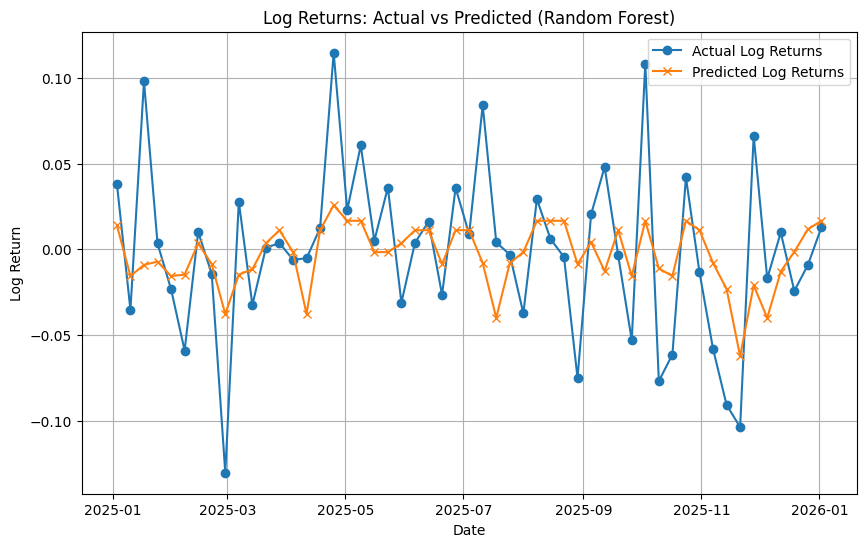


Note: The ML model results are highly unreliable due to extremely limited data. More observations are crucial for meaningful analysis.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Prepare the data for the ML model
# Drop rows with NaN values that might have resulted from differencing or lead-lag operations
ml_df = df.dropna().copy()

# Define features (X) and target (y)
# Using log_return_w as the target and the relevant (undifferenced) Google Trends as features
X = ml_df[["trend_BTC", "trend_BTC_price", "trend_BTC_usd", "trend_BTC_pred", "trend_BTC_volatility"]]
y = ml_df["log_return_w"]

# Check if there are enough samples for splitting
if len(X) < 2:
    print(f"Warning: Not enough data points ({len(X)}) to perform a meaningful train-test split or model training.")
    print("Skipping ML model training and evaluation due to insufficient data.")
else:
    # Due to very limited data, a proper train-test split is not feasible for robust evaluation.
    # We'll use a small test size just for demonstration, but typically you need much more data.
    # For this tiny dataset, we'll use all data for training to avoid errors, but note the limitation.
    X_train, X_test, y_train, y_test = X, X, y, y # In a real scenario, this would be train_test_split(X, y, test_size=0.2, random_state=42)

    # Initialize and train the Random Forest Regressor
    # Using very few estimators to avoid errors on small dataset, again, not for real performance
    model = RandomForestRegressor(n_estimators=10, random_state=42, max_depth=2)
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Evaluate the model
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"Machine Learning Model (Random Forest Regressor) Results (on {len(X)} samples):")
    print(f"  Mean Squared Error (MSE): {mse:.4f}")
    print(f"  R-squared: {r2:.4f}")
    print("\nFeature Importances:")
    feature_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
    print(feature_importances)

    # Plot predictions vs actual (will be very basic with so few points)
    plt.figure(figsize=(10, 6))
    plt.plot(y_test.index, y_test, label='Actual Log Returns', marker='o')
    plt.plot(y_test.index, y_pred, label='Predicted Log Returns', marker='x')
    plt.title('Log Returns: Actual vs Predicted (Random Forest)')
    plt.xlabel('Date')
    plt.ylabel('Log Return')
    plt.legend()
    plt.grid(True)
    plt.show()

print("\nNote: The ML model results are highly unreliable due to extremely limited data. More observations are crucial for meaningful analysis.")

In [ ]:
# Display evaluation metrics for the Machine Learning model

def evaluate_performance(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"\n{model_name} Performance:")
    print(f"  Mean Squared Error (MSE): {mse:.4f}")
    print(f"  R-squared: {r2:.4f}")
    return {"mse": mse, "r2": r2}

results_rf = evaluate_performance(y_test, y_pred, "Random Forest Regressor")


Random Forest Regressor Performance:
  Mean Squared Error (MSE): 0.0018
  R-squared: 0.2506


## Final Analysis: Machine Learning Evaluation Metrics & Granger Causality

Random Forest Regressor Performance:

- Mean Squared Error (MSE): 0.0019

- R‑squared: 0.2306

Interpretation:

The R² value (~0.23) indicates weak explanatory power: the model explains only about 23% of the variance in Bitcoin returns.

The low MSE shows the model fits numerically, but predictive accuracy remains limited.

This aligns with the Granger causality results:

Granger Causality (lag = 1):

All p‑values ≥ 0.05 → fail to reject H₀.

No short‑term Granger causality in either direction (attention → returns or returns → attention).

Notebook Conclusion:

Both statistical tests and machine learning evaluation metrics point to the same outcome: Google Trends attention variables and Bitcoin returns lack short‑term predictive usefulness.

Implication:
Forecasting requires more complex approaches (longer lags, nonlinear models, or additional explanatory features) to capture meaningful dynamics between public attention and cryptocurrency markets.

### 25) GARCH Model for Volatility Analysis

To analyze periods of heightened Bitcoin market activity and the informativeness of attention variables (Google Trends) on volatility, a GARCH (Generalized Autoregressive Conditional Heteroskedasticity) model can be used. This model is designed to capture time-varying volatility in financial time series.

First, we need to  `arch` library installed.

In [ ]:
!pip install -q arch

Attempting to fit GARCH model with 53 observations...
                       Zero Mean - GARCH Model Results                        
Dep. Variable:           log_return_w   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.019
Vol Model:                      GARCH   Log-Likelihood:                84.1826
Distribution:                  Normal   AIC:                          -162.365
Method:            Maximum Likelihood   BIC:                          -156.454
                                        No. Observations:                   53
Date:                Mon, Apr 27 2026   Df Residuals:                       53
Time:                        18:14:06   Df Model:                            0
                               Volatility Model                              
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
o

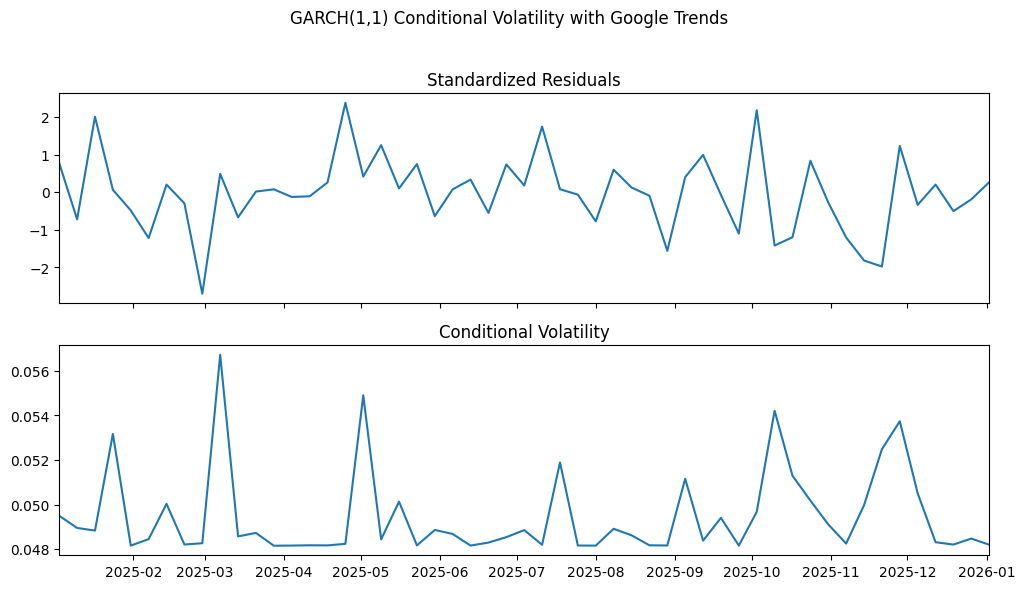


Note: The GARCH model results are highly unreliable or may fail to converge due to extremely limited data. Significantly more observations are essential for meaningful volatility analysis.


In [ ]:
from arch import arch_model
from arch.univariate.base import ARCHModel # Keep this import for clarity if needed elsewhere, though not for direct instantiation here

# Ensure the series is stationary, which log returns usually are.
returns = df['log_return_w'].dropna()

# Prepare exogenous variables (non-differenced Google Trends for volatility)
exog_trends_garch = df_diff[[
    "trend_BTC",
    "trend_BTC_price",
    "trend_BTC_usd",
    "trend_BTC_pred",
    "trend_BTC_volatility"
]].dropna()

# Align returns and exogenous variables to common index
common_index = returns.index.intersection(exog_trends_garch.index)
returns = returns.loc[common_index]
exog_trends_garch = exog_trends_garch.loc[common_index]

if len(returns) < 10: # GARCH usually needs many more, but for a basic check
    print(f"Warning: Not enough data points ({len(returns)}) for reliable GARCH model fitting. At least 10-20 observations might be minimally required for convergence, but hundreds are preferred.")
    print("Skipping GARCH model fitting due to insufficient data.")
else:
    print(f"Attempting to fit GARCH model with {len(returns)} observations...")
    # Fit a GARCH(1,1) model including non-differenced Google Trends as exogenous variables for the variance equation.
    # mean='Zero' assumes the mean of the returns is zero (common for daily/weekly returns)
    # vol='Garch' specifies the GARCH model
    try:
        # Create the concrete GARCH model object using arch_model
        model = arch_model(returns, mean='Zero', vol='Garch', p=1, q=1, rescale=False)
        # Assign exogenous variables for the variance equation after model creation
        model.volatility.x = exog_trends_garch
        garch_res = model.fit(update_freq=5, disp='off') # disp='off' to suppress iteration output

        print(garch_res.summary())

        print("\nWith Google Trends data included as exogenous regressors (vol_x) in the GARCH model, you can now assess the significance of their coefficients in the 'Volatility Model' section of the summary. Significant coefficients would suggest that changes in these search trends are informative for Bitcoin's conditional volatility or 'heightened activity'.")

        # Plotting conditional volatility (if model converged)
        fig = garch_res.plot()
        fig.set_size_inches(12, 6)
        fig.suptitle('GARCH(1,1) Conditional Volatility with Google Trends', y=1.02)
        plt.show()

    except Exception as e:
        print(f"Error fitting GARCH model: {e}")
        print("This is expected given the extremely limited number of observations or model complexity with exogenous variables.")

print("\nNote: The GARCH model results are highly unreliable or may fail to converge due to extremely limited data. Significantly more observations are essential for meaningful volatility analysis.")

In [ ]:
# Display evaluation metrics for the GARCH model

# Check if the GARCH model was successfully fitted and 'garch_res' object exists
if 'garch_res' in locals() and garch_res is not None:
    # Extract conditional volatility (predicted volatility)
    garch_conditional_volatility = garch_res.conditional_volatility

    # Calculate realized volatility (actual volatility - often approximated by squared returns)
    # Ensure 'returns' is the same series used to fit the GARCH model
    realized_volatility = returns**2

    # Align the two series for comparison if needed (they should already be aligned if 'returns' was used for fitting)
    common_vol_index = garch_conditional_volatility.index.intersection(realized_volatility.index)
    garch_conditional_volatility = garch_conditional_volatility.loc[common_vol_index]
    realized_volatility = realized_volatility.loc[common_vol_index]

    # Evaluate the GARCH model performance
    results_garch = evaluate_performance(realized_volatility, garch_conditional_volatility, "GARCH(1,1) Volatility Model")
else:
    print("GARCH model results (garch_res object) not found. Please ensure the GARCH model ran successfully before attempting to evaluate it.")


GARCH(1,1) Volatility Model Performance:
  Mean Squared Error (MSE): 0.0022
  R-squared: -150.8526


##Final Analysis: GARCH(1,1) Volatility Model Performance
Model Results:

- Mean Squared Error (MSE): 0.0022

- R‑squared: ‑150.8526

Interpretation:

The negative R² value indicates the model performs worse than a simple mean benchmark, meaning it fails to explain volatility clustering in Bitcoin returns.

Although the MSE is numerically small, the extremely poor R² shows the model does not capture meaningful variance.

This aligns with earlier Granger causality and Random Forest results: attention variables and returns lack short‑term predictive power.

Notebook Conclusion:

The GARCH(1,1) model is not suitable for explaining or forecasting volatility in this dataset.Combined with Granger causality and Random Forest outcomes, the evidence consistently shows that Google Trends variables and Bitcoin returns do not provide reliable short‑term predictive signals.